# Melbourne Housing · Comparación de los tres modelos

## Objetivo y recorrido del notebook

Este notebook reúne el trabajo de los tres bloques del proyecto y conserva su estructura original: primero se explica el objetivo general; después se desarrolla cada modelo con **su propio procesamiento de datos y las cuatro preguntas de negocio**; por último se comparan los resultados de los tres enfoques.

Los tres bloques parten del mismo conjunto limpio, `melbourne_limpio.csv`, con **27.246 viviendas y 15 columnas**. La variable que se intenta explicar o predecir es `Price` (precio de venta en AUD). Las 14 variables restantes describen características físicas, localización, tipo de operación y algunos indicadores que identifican valores imputados.

### Las cuatro preguntas que guían el análisis

1. **Predicción del precio:** ¿hasta qué punto podemos estimar el precio de una vivienda y con qué error?
2. **Factores del precio:** ¿qué características aportan más información para explicar el precio y cuáles se asocian con precios mayores o menores?
3. **Tipología:** ¿qué tipo de vivienda presenta un mayor valor por metro cuadrado construido?
4. **Terrenos:** ¿sería rentable adquirir una parcela y construir una vivienda bajo los supuestos de costes definidos en cada bloque?

### Cómo se organiza la comparación

- **Bloque 1 — Validación cruzada y regularización:** regresión lineal, Ridge y Lasso. Convierte las categorías en variables indicadoras y estandariza las variables para ajustar modelos lineales.
- **Bloque 2 — Random Forest:** combina árboles de decisión y aprende relaciones no lineales. Convierte las variables categóricas mediante *one-hot encoding*.
- **Bloque 3 — CatBoost:** utiliza árboles potenciados y procesa directamente las variables categóricas, después de seleccionar hiperparámetros mediante una búsqueda en rejilla.

Cada bloque mantiene su propio preprocesamiento, entrenamiento y evaluación, porque esas decisiones forman parte del método que se está comparando. Al final se presenta una síntesis visual de las cuatro preguntas.

### Criterios para interpretar los resultados

- **RMSE y MAE:** se expresan en AUD; cuanto menores, mejor. El RMSE penaliza especialmente los errores grandes.
- **R²:** mide la proporción de variabilidad del precio explicada por el modelo; cuanto más próximo a 1, mejor.
- **Importancia y coeficientes:** no son exactamente la misma medida. Los coeficientes de los modelos lineales expresan dirección y magnitud en la escala transformada; las importancias de los árboles indican cuánto utiliza el modelo cada variable. No deben compararse como si fueran porcentajes equivalentes.
- **Precio por m²:** se usa como indicador proxy de valor económico por superficie, no como beneficio neto, porque el dataset no contiene todos los costes de compra, obra, impuestos y venta.
- **Rentabilidad del terreno:** es una simulación basada en supuestos. No hay una observación directa de parcelas vacías con una construcción posterior.

> **Importante:** las cifras finales que aparecen en la comparación se han transcrito de los resultados guardados en los tres notebooks originales. Los procedimientos y las muestras no son idénticos en todas las preguntas; las diferencias metodológicas se señalan para evitar conclusiones engañosas. Al ejecutar todas las celdas, los resultados se volverán a calcular con los archivos del proyecto.

---
# Bloque 1 · Validación cruzada y regularización

## Qué hace este bloque

Este bloque estudia la predicción del precio mediante **regresión lineal múltiple**, **Ridge** y **Lasso**. La regresión lineal sirve como referencia; Ridge penaliza los coeficientes grandes para estabilizar el modelo; Lasso puede reducir algunos coeficientes exactamente a cero y, por tanto, seleccionar variables.

La validación cruzada K-Fold permite observar cómo cambia el rendimiento cuando se modifica la partición de los datos. Se utilizan particiones reproducibles para que las comparaciones internas sean consistentes. Además, se reserva un conjunto de prueba que no participa en el ajuste.

### Procesamiento de datos propio del bloque

1. Se carga `melbourne_limpio.csv`.
2. `Type`, `Suburb`, `Method` y `SellerG` se convierten en columnas indicadoras con `get_dummies(drop_first=True)`.
3. Se separan las variables predictoras (`X`) y el precio objetivo (`y`).
4. Se divide la muestra en entrenamiento (80 %) y prueba (20 %), con `random_state=42`.
5. `StandardScaler` se ajusta únicamente con entrenamiento y se aplica después a prueba, evitando que la información del test influya en el escalado.
6. Ridge y Lasso seleccionan el parámetro de regularización `alpha` mediante validación cruzada.

A continuación se conserva el análisis original del bloque: elección de K, comparación de modelos, coeficientes, tipologías y simulación de terrenos.

In [ ]:
# Librerías de siempre
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# Herramientas de scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy import stats                  # para el contraste de significación

sns.set_theme(style="whitegrid")

## 1. Datos

`melbourne_limpio.csv` ya está limpio y sin nulos (generado por `src/read_csv.py`). Las columnas `*_imputado` indican qué valores eran huecos.

In [ ]:
# El notebook está en models/, así que subimos una carpeta para llegar a datasets/
BASE = Path.cwd().parent
df = pd.read_csv(BASE / "datasets" / "melbourne_limpio.csv")

# Columnas de texto: habrá que convertirlas a números para los modelos lineales
CATEGORICAS = ["Type", "Suburb", "Method", "SellerG"]
print(f"Dimensiones: {df.shape[0]} viviendas x {df.shape[1]} columnas")
print(df.head())

Dimensiones: 27246 viviendas x 15 columnas
   Rooms  Bathroom  Car  Landsize  BuildingArea  YearBuilt  Distance  \
0    2.0       1.0  1.0     202.0          96.0     1900.0       2.5   
1    2.0       1.0  0.0     156.0          79.0     1900.0       2.5   
2    3.0       2.0  0.0     134.0         150.0     1900.0       2.5   
3    3.0       2.0  1.0      94.0         130.0     1900.0       2.5   
4    4.0       1.0  2.0     120.0         142.0     2014.0       2.5   

   BuildingArea_imputado  Landsize_imputado  Bathroom_imputado Type  \
0                      1                  0                  0    h   
1                      0                  0                  0    h   
2                      0                  0                  0    h   
3                      1                  0                  0    h   
4                      0                  0                  0    h   

       Suburb Method SellerG      Price  
0  Abbotsford      S  Biggin  1480000.0  
1  Abbotsford

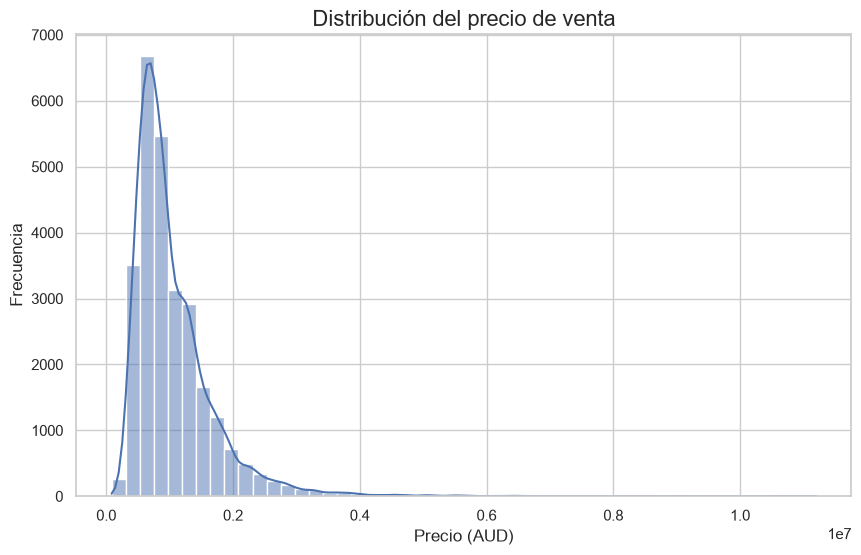

Mediana: 870,000 AUD   Máximo: 11,200,000 AUD   Asimetría: 2.59


In [ ]:
# Distribución del precio: si está sesgada, el RMSE lo dominarán las casas caras
plt.figure(figsize=(10, 6))
sns.histplot(df["Price"], kde=True, bins=50)
plt.title("Distribución del precio de venta", fontsize=16)
plt.xlabel("Precio (AUD)")
plt.ylabel("Frecuencia")
plt.show()

print(f"Mediana: {df['Price'].median():,.0f} AUD   "
      f"Máximo: {df['Price'].max():,.0f} AUD   "
      f"Asimetría: {df['Price'].skew():.2f}")

## Preparación de los datos

1. **Texto → columnas 0/1** con `get_dummies` (`drop_first=True`, la regresión lineal lo necesita).
2. **Separar `X` e `y`.**
3. **Dividir en train y test primero**, y después **escalar ajustando el `StandardScaler` solo con train** (como en el ejercicio 3).
4. Comprobar la **relación filas/columnas**: nos dirá si la regularización puede aportar algo.

In [ ]:
# 1. Categóricas -> columnas 0/1
#    drop_first=True quita una categoría de cada columna: queda como referencia (si Type_t = 0 y Type_u = 0, es una casa)
df_modelo = pd.get_dummies(df, columns=CATEGORICAS, drop_first=True, dtype=int)

# 2. Separar X e y
X = df_modelo.drop("Price", axis=1)
y = df_modelo["Price"]
columnas = list(X.columns)   # guardamos los nombres para leer los coeficientes más adelante

# 3. PRIMERO se divide en train y test (con datos sin escalar)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# El scaler se ajusta SOLO con train y se aplica a ambos
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"Entrenamiento: {X_train_s.shape[0]} viviendas")
print(f"Prueba:        {X_test_s.shape[0]} viviendas")
print(f"Columnas:      {X_train_s.shape[1]}")

# 4. Relación filas/columnas: cuantas más filas por columna, menos aporta la regularización (ejercicio 3)
ratio = X_train_s.shape[0] / X_train_s.shape[1]
print(f"\nRelación filas/columnas en entrenamiento: {ratio:.0f} a 1")

Entrenamiento: 21796 viviendas
Prueba:        5450 viviendas
Columnas:      707

Relación filas/columnas en entrenamiento: 31 a 1


## 2. Modelos

Misma rejilla de `alphas` en escala logarítmica para Ridge y Lasso (lo que importa es el orden de magnitud). `LassoCV` y `RidgeCV` eligen `alpha` con validación cruzada interna.

In [ ]:
# 13 valores de alpha entre 0,000001 y 1.000.000 (escala logarítmica)
alphas = np.logspace(-6, 6, 13)

# Diccionario con los modelos: así podemos recorrerlos todos con un bucle
modelos = {
    "LinearRegression": LinearRegression(),
    "RidgeCV": RidgeCV(alphas=alphas, scoring="neg_mean_squared_error"),       # no acepta random_state ni necesita cv
    "LassoCV": LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=10000),   # max_iter alto para que converja
}

## 1.1 · Predice el precio medio de una vivienda

### Elección del número de folds

Antes de poner 5 por costumbre: media y dispersión del RMSE de la regresión lineal según K, frente al tiempo. Más folds = más entrenamientos (más coste) y folds de validación más pequeños (más ruidosos).

In [ ]:
import time

filas_k = []
for k in (3, 5, 10, 20):
    t0 = time.time()   # cronómetro: más folds = más entrenamientos = más tiempo
    scores = cross_val_score(LinearRegression(), X_train_s, y_train,
                             cv=KFold(k, shuffle=True, random_state=42), scoring="neg_mean_squared_error")
    rmse_k = np.sqrt(-scores)   # el error viene en negativo: le cambiamos el signo antes de la raíz
    filas_k.append({"K": k, "RMSE medio": rmse_k.mean(), "Desv. típica": rmse_k.std(),
                    "Desv./media (%)": 100 * rmse_k.std() / rmse_k.mean(), "Tiempo (s)": time.time() - t0})
pd.DataFrame(filas_k).set_index("K").round(2)

,RMSE medio,Desv. típica,Desv./media (%),Tiempo (s)
K,,,,
3,369334.89,21977.24,5.95,10.04
5,367237.33,25544.67,6.96,4.36
10,367492.36,29792.93,8.11,9.48
20,366441.59,36877.70,10.06,23.28


### Validación cruzada de los tres modelos

Las **mismas particiones** (`KFold` con semilla fija) para todos, así las diferencias entre modelos no se deben a que les tocaron filas distintas. Como scikit-learn siempre maximiza, las métricas de error vienen en negativo: hay que cambiarles el signo.

In [ ]:
# Las mismas 5 particiones para todos los modelos (semilla fija)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# cross_validate permite pedir varias métricas a la vez (cross_val_score solo una)
scoring = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

# folds guarda, para cada modelo, el valor de cada métrica en cada fold
folds = {}
for nombre, modelo in modelos.items():
    res = cross_validate(modelo, X_train_s, y_train, cv=kf, scoring=scoring)   # solo train: el test no se toca
    folds[nombre] = {"RMSE": -res["test_RMSE"], "MAE": -res["test_MAE"], "R2": res["test_R2"]}


# RMSE de cada fold: si bailan mucho, la estimación es poco fiable
for nombre, f in folds.items():
    print(f"----- {nombre} -----")
    print("RMSE de cada fold: " + "  ".join(f"{r:,.0f}" for r in f["RMSE"]))
    print(f"RMSE promedio (CV): {f['RMSE'].mean():,.0f}   Desviación típica (CV): {f['RMSE'].std():,.0f}\n")

# Tabla resumen: media y desviación típica de cada métrica
resumen = pd.DataFrame({nombre: {f"{m} media": f[m].mean() for m in f} | {f"{m} desv.": f[m].std() for m in f}
                        for nombre, f in folds.items()}).T
resumen[["RMSE media", "RMSE desv.", "MAE media", "MAE desv.", "R2 media", "R2 desv."]].round(3)

c:\Users\aleja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.891891e+12, tolerance: 5.734e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\aleja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.108136e+12, tolerance: 5.578e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\aleja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iteration

----- LinearRegression -----
RMSE de cada fold: 409,252  370,766  370,515  354,711  330,943
RMSE promedio (CV): 367,237   Desviación típica (CV): 25,545

----- RidgeCV -----
RMSE de cada fold: 408,570  369,902  369,910  353,474  330,330
RMSE promedio (CV): 366,437   Desviación típica (CV): 25,577

----- LassoCV -----
RMSE de cada fold: 409,027  369,594  369,206  352,647  329,729
RMSE promedio (CV): 366,040   Desviación típica (CV): 25,955



,RMSE media,RMSE desv.,MAE media,MAE desv.,R2 media,R2 desv.
LinearRegression,367237.332,25544.667,230896.591,4287.404,0.676,0.018
RidgeCV,366437.209,25577.228,229951.971,4216.759,0.677,0.019
LassoCV,366040.499,25955.303,228345.213,4285.924,0.678,0.019


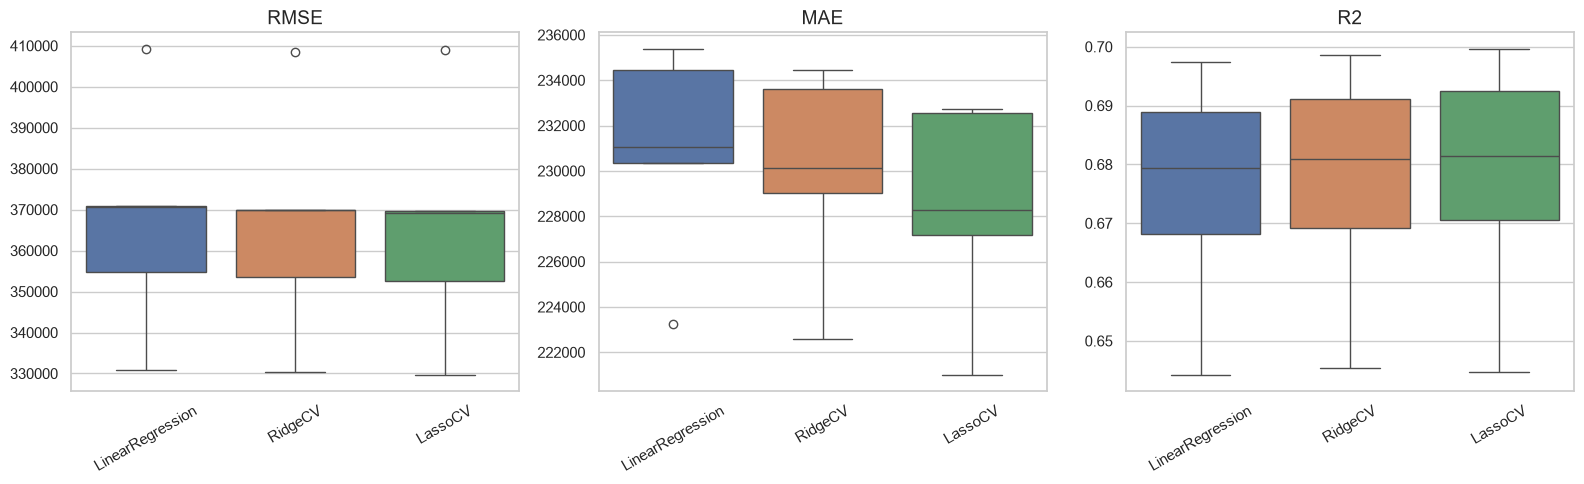

In [ ]:
# Un boxplot por métrica: la altura de cada caja es la dispersión entre folds
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for i, m in enumerate(["RMSE", "MAE", "R2"]):
    sns.boxplot(data=pd.DataFrame({n: f[m] for n, f in folds.items()}), ax=ax[i])
    ax[i].set_title(m, fontsize=14)
    ax[i].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### ¿Las diferencias son significativas o se deben al azar?

Comparamos fold a fold (son las mismas particiones). Si la diferencia media entre dos modelos es pequeña frente a la dispersión entre folds, puede ser azar.

Una t pareada normal se pasa de optimista, porque los folds comparten filas de entrenamiento. Usamos la **t corregida** (Nadeau y Bengio), que infla la varianza para tenerlo en cuenta.

In [ ]:
from itertools import combinations

def t_corregida(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b)   # diferencia fold a fold entre los dos modelos
    k = len(d)
    # El término n_test / n_train infla la varianza porque los folds comparten filas
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1))
    return t, 2 * stats.t.sf(abs(t), df=k - 1)   # devuelve t y su p-valor (dos colas)

# Tamaño de cada fold de validación y de entrenamiento
n_test_fold = len(X_train_s) // 5
n_train_fold = len(X_train_s) - n_test_fold
pares = list(combinations(folds, 2))   # todas las parejas de modelos

filas = []
for a, b in pares:
    d = folds[a]["RMSE"] - folds[b]["RMSE"]
    t, p = t_corregida(folds[a]["RMSE"], folds[b]["RMSE"], n_train_fold, n_test_fold)
    filas.append({"Comparación": f"{a} vs {b}", "Dif. RMSE media": d.mean(), "Desv. dif.": d.std(),
                  "Folds que gana el 1º (de 5)": int((d < 0).sum()),
                  "p": p, "p (Bonferroni)": min(1.0, p * len(pares))})   # Bonferroni: comparamos muchos pares
contrastes = pd.DataFrame(filas).set_index("Comparación")
contrastes["¿Significativa (5 %)?"] = contrastes["p (Bonferroni)"] < 0.05
contrastes.round(4)

,Dif. RMSE media,Desv. dif.,Folds que gana el 1º (de 5),p,p (Bonferroni),¿Significativa (5 %)?
Comparación,,,,,,
LinearRegression vs RidgeCV,800.1224,237.4662,0,0.0109,0.0327,True
LinearRegression vs LassoCV,1196.8332,584.5979,0,0.0525,0.1574,False
RidgeCV vs LassoCV,396.7108,460.0710,1,0.3143,0.9430,False


### Y ahora sí, el conjunto de test, una sola vez

In [ ]:
# Entrenamos con todo el train y predecimos el test (una sola vez)
pred_test = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train_s, y_train)
    pred_test[nombre] = modelo.predict(X_test_s)

test = pd.DataFrame({nombre: {"RMSE test": np.sqrt(mean_squared_error(y_test, p)),
                              "MAE test": mean_absolute_error(y_test, p),
                              "R2 test": r2_score(y_test, p),
                              "Precio medio predicho": p.mean()}
                     for nombre, p in pred_test.items()}).T
print(f"Precio medio real (test): {y_test.mean():,.0f} AUD")
print(f"Alpha Ridge: {modelos['RidgeCV'].alpha_:,.6f}   Alpha Lasso: {modelos['LassoCV'].alpha_:,.6f}")
test.round(3)

c:\Users\aleja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.238292e+13, tolerance: 7.446e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\aleja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.064902e+13, tolerance: 7.157e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\aleja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iteration

Precio medio real (test): 1,046,728 AUD
Alpha Ridge: 100.000000   Alpha Lasso: 1,000.000000


,RMSE test,MAE test,R2 test,Precio medio predicho
LinearRegression,342652.097,223730.561,0.701,1042388.744
RidgeCV,342481.116,223462.105,0.702,1043125.403
LassoCV,342261.711,221769.120,0.702,1043669.411


## 1.2 · ¿Qué características encarecen una vivienda?

In [ ]:
# 5 columnas de ruido (misma semilla que en clase, así el experimento es reproducible)
np.random.seed(42)
X_train_r = np.hstack((X_train_s, np.random.rand(X_train_s.shape[0], 5)))
X_test_r = np.hstack((X_test_s, np.random.rand(X_test_s.shape[0], 5)))
columnas_r = columnas + [f"ruido_{i + 1}" for i in range(5)]

# Lasso y Ridge entrenados con el ruido incluido
lasso_cv = LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=10000).fit(X_train_r, y_train)
ridge_cv = RidgeCV(alphas=alphas, scoring="neg_mean_squared_error").fit(X_train_r, y_train)
print(f"Alpha Lasso: {lasso_cv.alpha_:,.6f}   Alpha Ridge: {ridge_cv.alpha_:,.6f}")

c:\Users\aleja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.238085e+13, tolerance: 7.446e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\aleja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.064482e+13, tolerance: 7.157e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\aleja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iteration

Alpha Lasso: 1,000.000000   Alpha Ridge: 100.000000


Coeficientes a cero: 204 de 712

Coeficientes de las variables de ruido:
ruido_1   -0.0
ruido_2    0.0
ruido_3    0.0
ruido_4   -0.0
ruido_5   -0.0
dtype: float64
¿Las 5 de ruido están a cero? True

Variables reales descartadas: 199
  + 48 barrios y 151 inmobiliarias


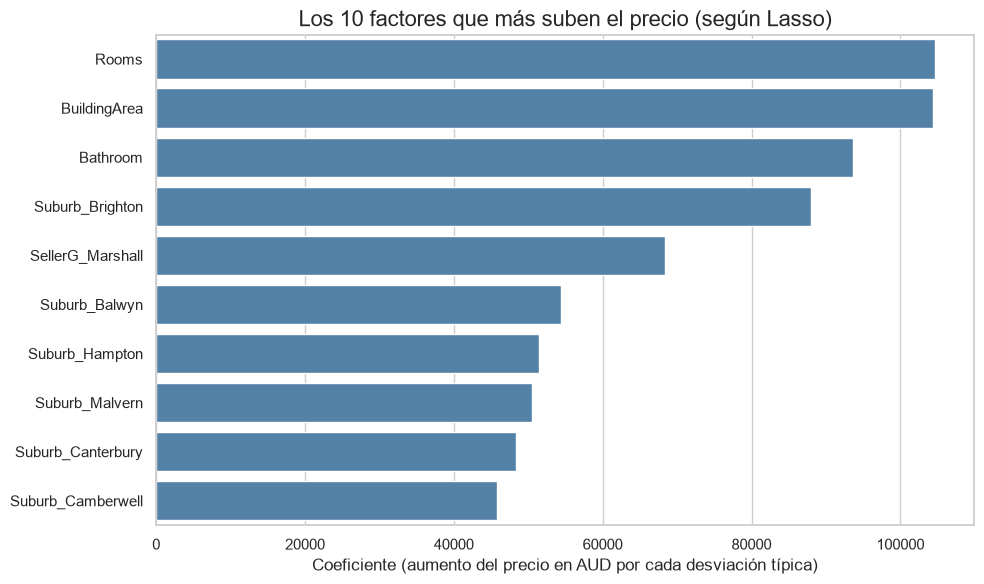

In [ ]:
# 1. Coeficientes del Lasso en una Series, indexada por nombre de variable
coefs = pd.Series(lasso_cv.coef_, index=columnas_r)

# 2. Cuántos coeficientes son cero
n_ceros = (coefs == 0).sum()
print(f"Coeficientes a cero: {n_ceros} de {len(coefs)}")

# 3. Qué ha pasado con las 5 variables de ruido
es_ruido = coefs.index.str.startswith("ruido_")   # máscara booleana: True solo en las 5 de ruido
coefs_ruido = coefs[es_ruido]                     # nos quedamos con los True
print("\nCoeficientes de las variables de ruido:")
print(coefs_ruido)
print(f"¿Las 5 de ruido están a cero? {(coefs_ruido == 0).all()}")

# 4. Variables reales que Lasso ha descartado (sin contar dummies de Suburb y SellerG, que son cientos)
coefs_reales = coefs[~es_ruido]   # ~ invierte la máscara: todas menos las de ruido
descartadas = coefs_reales[coefs_reales == 0].index.tolist()
print(f"\nVariables reales descartadas: {len(descartadas)}")
for nombre in [d for d in descartadas if not d.startswith(("Suburb_", "SellerG_"))]:
    print(f"  - {nombre}")
print(f"  + {sum(d.startswith('Suburb_') for d in descartadas)} barrios y "
      f"{sum(d.startswith('SellerG_') for d in descartadas)} inmobiliarias")

# 5. Top 10 de coeficientes positivos más grandes
top10 = coefs.sort_values(ascending=False).head(10)   # ordenada de mayor a menor

plt.figure(figsize=(10, 6))
sns.barplot(x=top10.values, y=top10.index, color="steelblue")
plt.title("Los 10 factores que más suben el precio (según Lasso)", fontsize=16)
plt.xlabel("Coeficiente (aumento del precio en AUD por cada desviación típica)")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Ridge contra Lasso (ejercicio 2)

Ridge encoge todos los coeficientes pero **nunca los pone a cero exacto**; Lasso sí. Cuando dos variables miden casi lo mismo, Ridge reparte el peso y Lasso se queda con una.

In [ ]:
# Coeficientes de Ridge y recuento de ceros EXACTOS (no valores pequeños)
coefs_ridge = pd.Series(ridge_cv.coef_, index=columnas_r)
print(f"Coeficientes a cero RIDGE: {(coefs_ridge == 0).sum()} de {len(coefs_ridge)}")
print(f"Coeficientes a cero LASSO: {n_ceros} de {len(coefs)}")

# Ridge encoge el ruido pero no lo anula
print("\nCoeficientes de las variables de ruido RIDGE:")
print(coefs_ridge[es_ruido])
print(f"¿Las 5 de ruido están a cero? {(coefs_ridge[es_ruido] == 0).all()}")

Coeficientes a cero RIDGE: 0 de 712
Coeficientes a cero LASSO: 204 de 712

Coeficientes de las variables de ruido RIDGE:
ruido_1   -3300.784535
ruido_2    1394.909308
ruido_3    1707.404803
ruido_4   -1064.331914
ruido_5     -45.201281
dtype: float64
¿Las 5 de ruido están a cero? False


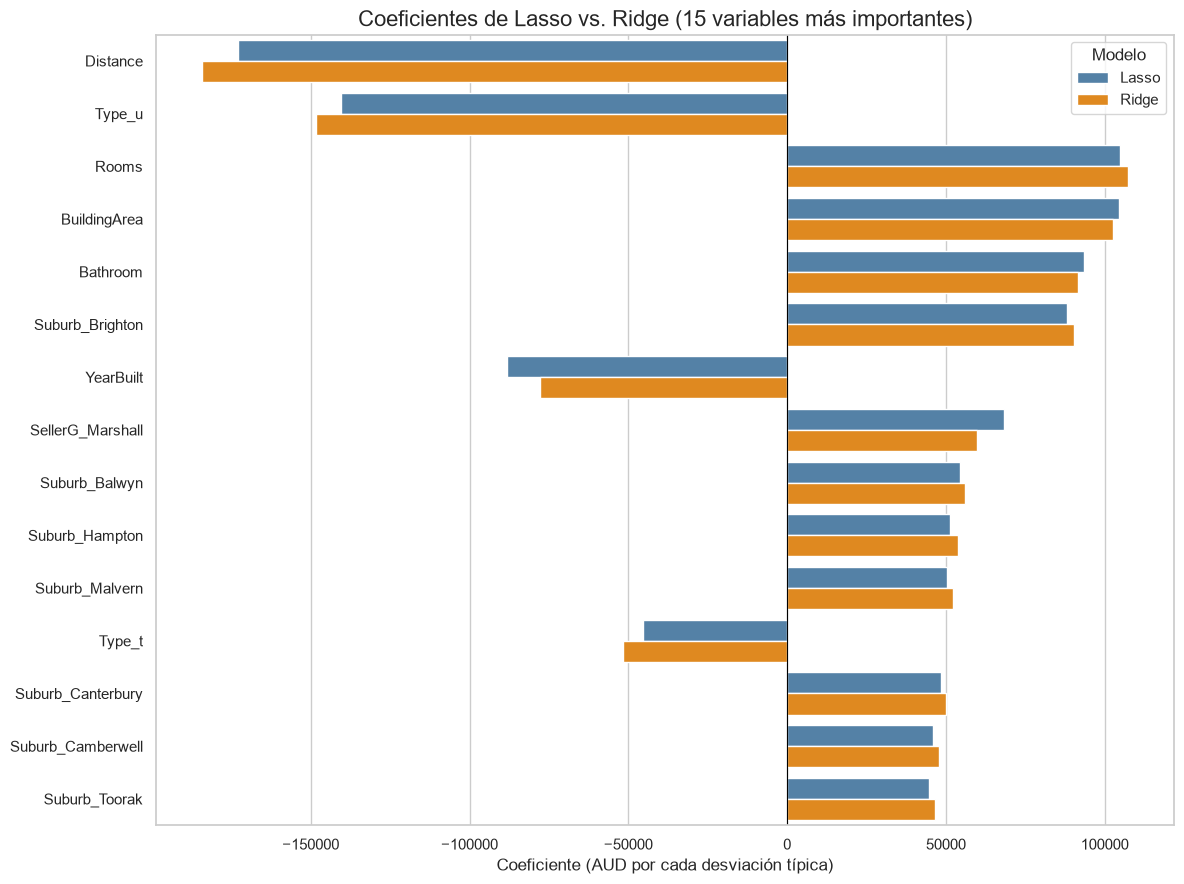

Variables que Lasso descarta pero Ridge conserva (|coef| > 9,205): 0


In [ ]:
comp = pd.DataFrame({"Lasso": coefs, "Ridge": coefs_ridge})

# Las 15 variables más importantes en valor absoluto (según el mayor de los dos modelos)
top15_idx = comp.abs().max(axis=1).sort_values(ascending=False).head(15).index
top15 = comp.loc[top15_idx]

# Formato largo para el gráfico de barras agrupadas
top15_largo = (top15.reset_index().rename(columns={"index": "Variable"})
               .melt(id_vars="Variable", var_name="Modelo", value_name="Coeficiente"))

plt.figure(figsize=(12, 9))
sns.barplot(data=top15_largo, x="Coeficiente", y="Variable", hue="Modelo",
            palette={"Lasso": "steelblue", "Ridge": "darkorange"})
plt.title("Coeficientes de Lasso vs. Ridge (15 variables más importantes)", fontsize=16)
plt.xlabel("Coeficiente (AUD por cada desviación típica)")
plt.ylabel("")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

# Casos donde Lasso dice cero y Ridge mantiene un coeficiente apreciable
umbral = 0.05 * comp["Ridge"].abs().max()   # "apreciable" = al menos el 5 % del mayor coeficiente de Ridge
discrepancias = comp[(comp["Lasso"] == 0) & (comp["Ridge"].abs() > umbral)]
discrepancias = discrepancias.reindex(discrepancias["Ridge"].abs().sort_values(ascending=False).index)
print(f"Variables que Lasso descarta pero Ridge conserva (|coef| > {umbral:,.0f}): {len(discrepancias)}")

## 1.3 · ¿Qué tipo de vivienda genera más beneficio?

Sin costes en el dataset, el indicador de **beneficio** es el **precio por m² construido**, solo con viviendas cuya superficie construida es real (no imputada):
- **Bruto:** mediana de `Price / BuildingArea` por tipo.
- **Controlado:** con cada modelo, las mismas viviendas de test cambiando **solo el tipo** (misma superficie, barrio, distancia, año...). Así la diferencia no se debe a dónde están ni a cómo son.

In [ ]:
# Solo viviendas de test con superficie construida real (BuildingArea_imputado = 0)
reales = X_test.index[df.loc[X_test.index, "BuildingArea_imputado"] == 0]
datos_13 = df.loc[reales].copy()
datos_13["precio_m2"] = datos_13["Price"] / datos_13["BuildingArea"]

# Indicador bruto: mediana por tipo
res_13 = datos_13.groupby("Type").agg(n=("Price", "size"), precio_mediano=("Price", "median"),
                                      m2_mediano=("BuildingArea", "median"), bruto_precio_m2=("precio_m2", "median"))

def matriz(datos):
    """Mismas columnas y escala que en el entrenamiento."""
    d = pd.get_dummies(datos.drop(columns="Price"), columns=CATEGORICAS, dtype=int)
    # reindex: añade con 0 las columnas que falten y quita las que sobren
    return scaler.transform(d.reindex(columns=columnas, fill_value=0))

for nombre in list(modelos):
    valores = {}
    for tipo in res_13.index:
        cambiado = datos_13.drop(columns="precio_m2").assign(Type=tipo)  # misma vivienda, solo cambia el tipo
        pred = modelos[nombre].predict(matriz(cambiado))
        valores[tipo] = np.median(pred / datos_13["BuildingArea"])   # precio predicho por m²
    res_13[f"controlado {nombre}"] = pd.Series(valores)

print("Tipo con mayor precio/m²:", {c: res_13[c].idxmax() for c in res_13.columns if "precio_m2" in c or "controlado" in c})
res_13.round(0)

Tipo con mayor precio/m²: {'bruto_precio_m2': 'u', 'controlado LinearRegression': 'h', 'controlado RidgeCV': 'h', 'controlado LassoCV': 'h'}


,n,precio_mediano,m2_mediano,bruto_precio_m2,controlado LinearRegression,controlado RidgeCV,controlado LassoCV
Type,,,,,,,
h,1538,1015000.0,150.0,7064.0,7887.0,7907.0,7852.0
t,187,840000.0,133.0,6487.0,6636.0,6651.0,6764.0
u,352,550500.0,76.0,7384.0,5174.0,5210.0,5331.0


## 1.4 · ¿Es rentable un terreno sin construir?

⚠️ No hay terrenos vacíos en el dataset. Entrenamos solo con **casas con superficie construida real** y estimamos:
- **Valor del m² construido:** cuánto sube la predicción al aumentar la superficie construida (±20 %).
- **Precio del terreno** = precio predicho de la casa − valor de lo construido.
- **Margen** = precio de mercado de la zona − terreno − coste de construir.

**Supuestos** (no salen del dataset): obra a **2.000 AUD/m²** y **15 %** de otros costes (permisos, tasas, imprevistos y venta).

In [ ]:
# Supuestos (cámbialos aquí)
COSTE_M2 = 2_000                               # AUD por m² construido
OTROS_COSTES = 0.15                            # 15 % extra sobre el coste de obra
SENSIBILIDAD = [1_500, 2_000, 2_500, 3_000, 3_500]   # costes a probar en la sensibilidad

# Solo casas (Type = h) con superficie construida real
casas = df[(df["Type"] == "h") & (df["BuildingArea_imputado"] == 0)].copy()
cat_14 = ["Suburb", "Method", "SellerG"]   # Type ya no hace falta: todas son casas

# Mismo proceso que antes: dummies + escalado, ahora solo con estas casas
d14 = pd.get_dummies(casas.drop(columns=["Price", "Type"]), columns=cat_14, drop_first=True, dtype=int)
columnas_14 = list(d14.columns)
scaler_14 = StandardScaler().fit(d14)

def matriz_14(datos):
    d = pd.get_dummies(datos.drop(columns=["Price", "Type"]), columns=cat_14, dtype=int)
    return scaler_14.transform(d.reindex(columns=columnas_14, fill_value=0))

X14, y14 = matriz_14(casas), casas["Price"]

# Los mismos tres modelos lineales, entrenados solo con las casas
modelos_14 = {
    "LinearRegression": LinearRegression(),
    "RidgeCV": RidgeCV(alphas=alphas, scoring="neg_mean_squared_error"),
    "LassoCV": LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=10000),
}
for m in modelos_14.values():
    m.fit(X14, y14)

# Predice con cualquiera de los tres modelos
def predecir_14(nombre, datos):
    return modelos_14[nombre].predict(matriz_14(datos))

def valor_m2(nombre, datos):
    """AUD que el modelo da a cada m² construido adicional (pendiente local, ±20 % de superficie)."""
    lo, hi = datos.copy(), datos.copy()
    lo["BuildingArea"] *= 0.8   # misma casa con un 20 % menos de superficie
    hi["BuildingArea"] *= 1.2   # ... y con un 20 % más
    # diferencia de precio / diferencia de m² = AUD por m²
    return (predecir_14(nombre, hi).mean() - predecir_14(nombre, lo).mean()) / (0.4 * datos["BuildingArea"].mean())

print(f"Casas con superficie construida real: {len(casas)}")

c:\Users\aleja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.318981e+12, tolerance: 2.992e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\aleja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.065649e+12, tolerance: 3.301e+11
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\aleja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iteration

Casas con superficie construida real: 7889


In [ ]:
# Región de cada barrio (no está en el CSV limpio)
region = pd.read_csv(BASE / "datasets" / "Melbourne_housing_FULL.csv").groupby("Suburb")["Regionname"].first()
casas["Regionname"] = casas["Suburb"].map(region)

filas = []
for nombre in modelos_14:
    # Primero todas las casas juntas y después región a región
    for zona, g in [("TODAS", casas)] + list(casas.groupby("Regionname")):
        g = g.drop(columns="Regionname")   # no es una variable del modelo
        b = valor_m2(nombre, g)
        terreno = np.median(predecir_14(nombre, g) - b * g["BuildingArea"])   # precio casa - valor de lo construido
        mercado = g["Price"].median()                                          # precio de mercado de la zona
        coste = g["BuildingArea"].median() * COSTE_M2 * (1 + OTROS_COSTES)     # construir una casa típica
        margen = mercado - terreno - coste                                     # > 0 -> rentable
        filas.append({"Modelo": nombre, "Zona": zona, "n": len(g), "valor_m2_construido": b,
                      "coste_max_m2_rentable": b / (1 + OTROS_COSTES), "terreno_estimado": terreno,
                      "precio_mercado": mercado, "terreno_%_precio": 100 * terreno / mercado,
                      "coste_construccion": coste, "margen_AUD": margen,
                      "margen_%_inversion": 100 * margen / (terreno + coste)})
res_14 = pd.DataFrame(filas).set_index(["Modelo", "Zona"])
res_14.round(0)

n  valor_m2_construido  \
Modelo           Zona                                                    
LinearRegression TODAS                       7889               1450.0   
                 Eastern Metropolitan        1005               1450.0   
                 Eastern Victoria              69               1450.0   
                 Northern Metropolitan       2291               1450.0   
                 Northern Victoria             90               1450.0   
                 South-Eastern Metropolitan   438               1450.0   
                 Southern Metropolitan       1969               1450.0   
                 Western Metropolitan        1968               1450.0   
                 Western Victoria              59               1450.0   
RidgeCV          TODAS                       7889               1390.0   
                 Eastern Metropolitan        1005               1390.0   
                 Eastern Victoria              69               1390.0   
                 Northern Metropolitan       2291               1390.0   
                 Northern Victoria             90               1390.0   
                 South-Eastern Metropolitan   438               1390.0   
                 Southern Metropolitan       1969               1390.0   
                 Western Metropolitan        1968               1390.0   
                 Western Victoria              59               1390.0   
LassoCV          TODAS                       7889               1467.0   
                 Eastern Metropolitan        1005               1467.0   
                 Eastern Victoria              69               1467.0   
                 Northern Metropolitan       2291               1467.0   
                 Northern Victoria             90               1467.0   
                 South-Eastern Metropolitan   438               1467.0   
                 Southern Metropolitan       1969               1467.0   
                 Western Metropolitan        1968               1467.0   
                 Western Victoria              59               1467.0   

                                             coste_max_m2_rentable  \
Modelo           Zona                                                
LinearRegression TODAS                                      1261.0   
                 Eastern Metropolitan                       1261.0   
                 Eastern Victoria                           1261.0   
                 Northern Metropolitan                      1261.0   
                 Northern Victoria                          1261.0   
                 South-Eastern Metropolitan                 1261.0   
                 Southern Metropolitan                      1261.0   
                 Western Metropolitan                       1261.0   
                 Western Victoria                           1261.0   
RidgeCV          TODAS                                      1209.0   
                 Eastern Metropolitan                       1209.0   
                 Eastern Victoria                           1209.0   
                 Northern Metropolitan                      1209.0   
                 Northern Victoria                          1209.0   
                 South-Eastern Metropolitan                 1209.0   
                 Southern Metropolitan                      1209.0   
                 Western Metropolitan                       1209.0   
                 Western Victoria                           1209.0   
LassoCV          TODAS                                      1276.0   
                 Eastern Metropolitan                       1276.0   
                 Eastern Victoria                           1276.0   
                 Northern Metropolitan                      1276.0   
                 Northern Victoria                          1276.0   
                 South-Eastern Metropolitan                 1276.0   
                 Southern Metropolitan                      1276.0   
           

### Sensibilidad al coste de construcción

Margen % sobre la inversión (todas las zonas) según el coste por m².

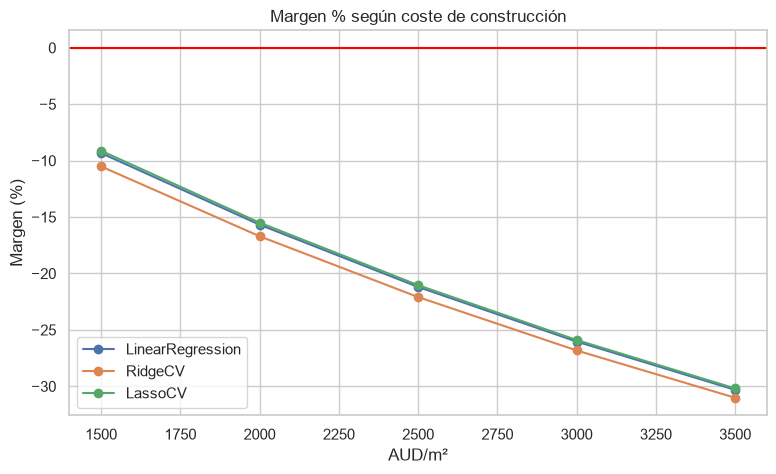

,LinearRegression,RidgeCV,LassoCV
AUD/m²,,,
1500,-9.3,-10.5,-9.1
2000,-15.7,-16.7,-15.5
2500,-21.2,-22.1,-21.0
3000,-26.0,-26.8,-25.9
3500,-30.3,-31.0,-30.2


In [ ]:
todas = casas.drop(columns="Regionname")

# Mismo cálculo que arriba (todas las zonas), repetido para cada coste por m²
sens = {}
for nombre in modelos_14:
    b = valor_m2(nombre, todas)
    terreno = np.median(predecir_14(nombre, todas) - b * todas["BuildingArea"])
    mercado, area = todas["Price"].median(), todas["BuildingArea"].median()
    sens[nombre] = {c: 100 * (mercado - terreno - area * c * (1 + OTROS_COSTES))
                       / (terreno + area * c * (1 + OTROS_COSTES)) for c in SENSIBILIDAD}
sens = pd.DataFrame(sens).rename_axis("AUD/m²")

sens.plot(marker="o", figsize=(9, 5), title="Margen % según coste de construcción")
plt.axhline(0, color="red")   # por encima de la línea roja, rentable
plt.ylabel("Margen (%)")
plt.show()
sens.round(1)

---
# Bloque 2 · Random Forest

## Qué hace este bloque

Random Forest construye un conjunto de árboles de decisión a partir de muestras aleatorias y combina sus predicciones. Este enfoque puede capturar relaciones no lineales e interacciones entre variables sin exigir que el efecto de cada característica sea lineal.

Primero se estudia la profundidad de los árboles para observar el equilibrio entre error de entrenamiento y error de prueba. Después se ajusta el modelo final y se evalúa mediante un conjunto de prueba y validación cruzada de cinco particiones.

### Procesamiento de datos propio del bloque

1. Se carga el mismo `melbourne_limpio.csv`.
2. Se transforman las variables categóricas mediante `get_dummies`.
3. Se separan `X` e `y` y se realiza una partición de entrenamiento/prueba.
4. Se exploran distintas profundidades (`max_depth`) y se selecciona la que ofrece el menor error de prueba dentro de la rejilla probada.
5. Se entrena el modelo final y se calcula su rendimiento.

A diferencia del bloque lineal, Random Forest no necesita estandarizar las variables para que las divisiones de los árboles funcionen correctamente. Las cuatro preguntas se resuelven con las predicciones y las herramientas de interpretación propias del modelo.

### Desarrollo del modelo Random Forest

El siguiente código corresponde al notebook original de Random Forest. Se mantiene su selección de profundidad, evaluación, interpretación, análisis de tipologías y simulación de terrenos.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")

## 1. Datos

`melbourne_limpio.csv` ya está limpio. Pasamos el texto a columnas 0/1 con `get_dummies` y separamos 80 % entrenamiento / 20 % prueba.

In [ ]:
from pathlib import Path

BASE = Path.cwd().parent
CLEAN_FILE = BASE / "datasets" / "melbourne_limpio.csv"
df = pd.read_csv(CLEAN_FILE)

df_modelo = pd.get_dummies(df, columns=["Type", "Suburb", "Method", "SellerG"], drop_first=True)
print(str(df_modelo.shape[0]) + "  " + str(df_modelo.shape[1]))
#print(df_modelo.head(4))
X = df_modelo.drop("Price", axis=1)
y = df_modelo["Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"{len(df)} viviendas | {df.shape[1]} columnas")

27246  708
27246 viviendas | 15 columnas


## 2. Elegir la profundidad (curva de error, como en S05)

Si el error de prueba deja de bajar mientras el de entrenamiento sigue bajando, hay sobreajuste.

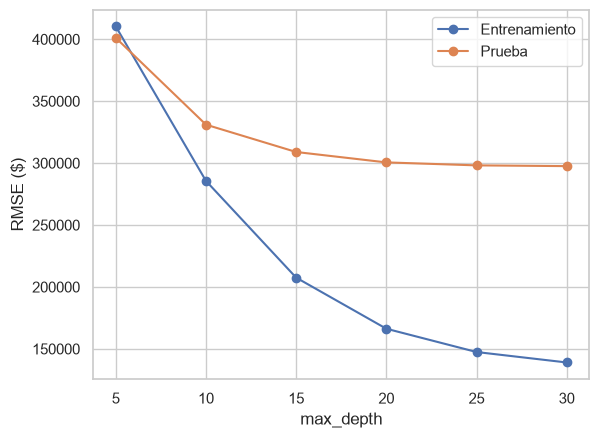

Mejor profundidad: 30


In [ ]:
profundidades = [5, 10, 15, 20, 25, 30]
rmse_train, rmse_test = [], []

for d in profundidades:
    rf = RandomForestRegressor(n_estimators=100, max_depth=d, random_state=42, n_jobs=-1).fit(X_train, y_train)
    rmse_train.append(np.sqrt(mean_squared_error(y_train, rf.predict(X_train))))
    rmse_test.append(np.sqrt(mean_squared_error(y_test, rf.predict(X_test))))

plt.plot(profundidades, rmse_train, "o-", label="Entrenamiento")
plt.plot(profundidades, rmse_test, "o-", label="Prueba")
plt.xlabel("max_depth"); plt.ylabel("RMSE ($)"); plt.legend()
plt.show()

mejor_profundidad = profundidades[np.argmin(rmse_test)]
print(f"Mejor profundidad: {mejor_profundidad}")

## 3. Modelo final y validación cruzada (5 folds)

In [ ]:
modelo_rf = RandomForestRegressor(n_estimators=300, max_depth=mejor_profundidad, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train, y_train)
pred_test = modelo_rf.predict(X_test)

print(f"RMSE prueba: {np.sqrt(mean_squared_error(y_test, pred_test)):,.0f} $")
print(f"MAE prueba:  {mean_absolute_error(y_test, pred_test):,.0f} $")
print(f"R² prueba:   {r2_score(y_test, pred_test):.3f}")

# Validación cruzada: 5 entrenamientos con una parte distinta de prueba cada vez
r2_cv = cross_val_score(RandomForestRegressor(n_estimators=100, max_depth=mejor_profundidad, random_state=42, n_jobs=-1),
                        X, y, cv=5, scoring="r2")
print(f"R² en los 5 folds: {np.round(r2_cv, 3)} -> media {r2_cv.mean():.3f}")

RMSE prueba: 295,634 $
MAE prueba:  181,026 $
R² prueba:   0.778
R² en los 5 folds: [0.722 0.686 0.724 0.714 0.734] -> media 0.716


## 1.1 · Predice el precio medio de una vivienda

Precio medio real:     1,046,728 $
Precio medio predicho: 1,040,336 $


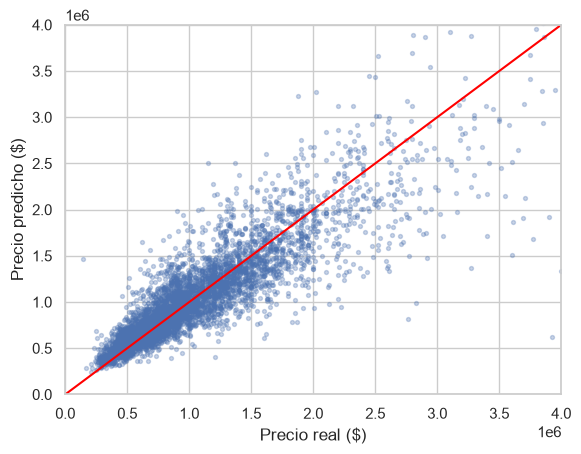

In [ ]:
print(f"Precio medio real:     {y_test.mean():,.0f} $")
print(f"Precio medio predicho: {pred_test.mean():,.0f} $")

plt.scatter(y_test, pred_test, alpha=0.3, s=8)
plt.plot([0, 4e6], [0, 4e6], color="red")
plt.xlim(0, 4e6); plt.ylim(0, 4e6)
plt.xlabel("Precio real ($)"); plt.ylabel("Precio predicho ($)")
plt.show()

**Conclusión.** El modelo explica el **78 %** de la variación del precio en prueba (R² 0,778) y se equivoca de media unos **181.000 $** (MAE). En la validación cruzada el R² se mantiene entre 0,69 y 0,73 en los 5 folds (media 0,72), así que el resultado es estable. El precio medio predicho (1.040.336 $) es casi igual al real (1.046.728 $). Donde más falla es en las viviendas muy caras, que tiende a predecir por debajo.

*Nota sobre la profundidad:* a partir de `max_depth=20` el error de prueba casi no baja (de ~300.000 $ a ~297.000 $), mientras el de entrenamiento sigue cayendo. Ganó 30, el extremo de la lista, pero la mejora es mínima.

## 1.2 · ¿Qué características encarecen una vivienda?

`feature_importances_` (S05/S06). Sumamos las columnas que vienen de la misma variable (todas las `Suburb_...` juntas).

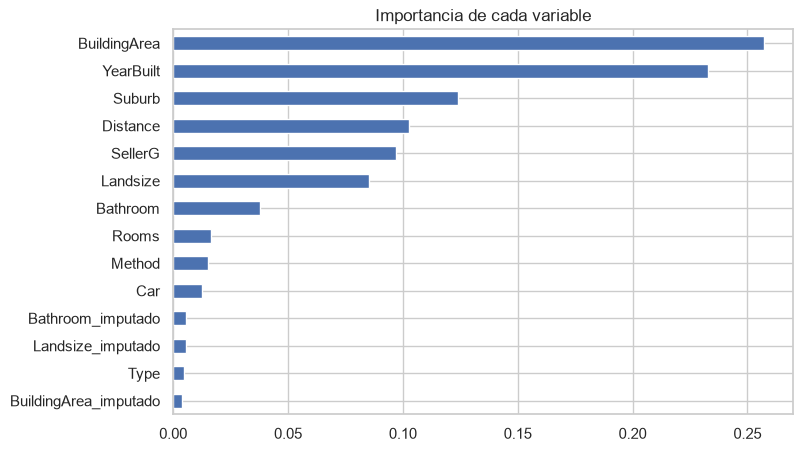

BuildingArea    0.54
Distance       -0.19
YearBuilt      -0.43
Landsize        0.05
Rooms           0.50
Price           1.00
Name: Price, dtype: float64

In [ ]:
importancias = pd.Series(modelo_rf.feature_importances_, index=X.columns)
importancias.index = [c.split("_")[0] if c.split("_")[0] in ["Type", "Suburb", "Method", "SellerG"] else c
                      for c in importancias.index]
importancias = importancias.groupby(level=0).sum().sort_values()

importancias.plot(kind="barh", figsize=(8, 5), title="Importancia de cada variable")
plt.show()

# ¿Sube o baja el precio? Correlación con el precio
df[["BuildingArea", "Distance", "YearBuilt", "Landsize", "Rooms", "Price"]].corr(method="spearman")["Price"].round(2)

**Conclusión.** Lo que más usa el modelo es la **superficie construida**, seguida del **año de construcción**, el **suburbio**, la **distancia al centro**, la **agencia** (`SellerG`) y la **parcela**. Con la correlación vemos la dirección: más m² y más habitaciones → más caro; más lejos del centro → más barato. El año sale con signo negativo (las casas antiguas son más caras) porque las casas antiguas están en los barrios céntricos: en realidad refleja la ubicación.

## 1.3 · ¿Qué tipo de vivienda genera más beneficio?

Sin costes en el dataset, usamos el **precio predicho por m² construido** (solo viviendas con superficie original, no imputada).

In [ ]:
prueba = df.loc[X_test.index].copy()
prueba["precio_m2"] = pred_test / prueba["BuildingArea"]
prueba = prueba[(prueba["BuildingArea_imputado"] == 0) & (prueba["BuildingArea"] >= 20)]

prueba.groupby("Type")[["precio_m2", "Price", "BuildingArea", "Landsize", "Distance"]].median().round(0)

,precio_m2,Price,BuildingArea,Landsize,Distance
Type,,,,,
h,7333.0,1020000.0,150.0,574.0,11.0
t,6408.0,840000.0,134.0,211.0,10.0
u,7683.0,550000.0,76.0,601.0,6.0


**Conclusión.** Por m² construido, las **unidades** (u) son las que más valen (~7.700 $/m²), seguidas de las **casas** (h, ~7.300 $/m²) y por último los **townhouses** (t, ~6.400 $/m²). Las unidades están más cerca del centro (6 km) y son pequeñas, por eso el m² sale caro. Las casas tienen el precio total más alto porque incluyen más suelo. Los townhouses tienen casi tanta superficie como una casa pero mucho menos suelo, y por eso rinden menos.

## 1.4 · ¿Es rentable un terreno sin construir?

Supuestos: obra a 2.200 $/m², construir el 50 % de la parcela (máx. 200 m²) y 12 % de permisos y financiación. **Margen = (valor nuevo − coste) / coste.** Rentable si > 15 %.

⚠️ No hay terrenos vacíos en el dataset: usamos casas con parcela ≥ 200 m² sin superficie construida original, así que equivale a comprar, derribar y construir.

In [ ]:
parcelas = df[(df["Type"] == "h") & (df["BuildingArea_imputado"] == 1) & (df["Landsize_imputado"] == 0) & (df["Landsize"] >= 200)].copy()

m2_nuevos = np.minimum(parcelas["Landsize"] * 0.5, 200)
coste = (parcelas["Price"] + m2_nuevos * 2200) * 1.12

# La misma parcela con una casa nueva
nueva = parcelas.assign(BuildingArea=m2_nuevos, YearBuilt=2026, BuildingArea_imputado=0).drop(columns="Price")
X_nueva = pd.get_dummies(nueva, columns=["Type", "Suburb", "Method", "SellerG"]).reindex(columns=X.columns, fill_value=0)

parcelas["margen_pct"] = (modelo_rf.predict(X_nueva) - coste) / coste * 100

print(f"{len(parcelas)} parcelas | margen mediano {parcelas['margen_pct'].median():.1f} % | rentables: {(parcelas['margen_pct'] > 15).mean() * 100:.1f} %")

por_suburbio = parcelas.groupby("Suburb")["margen_pct"].agg(["count", "median"])
por_suburbio[por_suburbio["count"] >= 5].sort_values("median", ascending=False).round(1).iloc[[0, 1, 2, 3, 4, -5, -4, -3, -2, -1]]

6009 parcelas | margen mediano -33.1 % | rentables: 0.3 %


,count,median
Suburb,,
Brooklyn,5,-5.9
Dallas,6,-11.3
Dingley Village,14,-13.0
Heidelberg West,46,-13.4
Spotswood,12,-15.5
Prahran,17,-53.1
St Kilda,16,-53.2
Mont Albert,16,-53.3
Middle Park,6,-57.9


**Conclusión.** Con estos supuestos **no es rentable**: el margen mediano es del **−33 %** y solo un 0,3 % de las parcelas supera el 15 %. Ningún suburbio llega a margen positivo; los menos malos son zonas con suelo barato (Brooklyn, Dallas, Heidelberg West) y los peores, zonas con suelo muy caro (Albert Park, Middle Park, St Kilda). Ojo: el modelo da menos valor a lo nuevo (lo nuevo suele estar lejos del centro), así que el resultado puede ser algo pesimista.

## Mapa

Viviendas de prueba sobre el mapa de Melbourne: 🟢 más de un 10 % por debajo de la predicción, 🔵 ±10 %, 🔴 más de un 10 % por encima. Clic en un punto para ver sus datos.

In [ ]:
import folium
import webbrowser
from folium.plugins import MarkerCluster

import subprocess, sys
from IPython.display import IFrame

BASE = Path.cwd().parent
CSV_FILE = BASE / "datasets" / "Melbourne_housing_FULL.csv"

# Coordenadas del dataset original (mismo orden que el limpio, sin las filas sin precio)
original = pd.read_csv(CSV_FILE).dropna(subset=["Price"]).reset_index(drop=True)
clave = ["Suburb", "Rooms", "Type", "Price", "Method", "SellerG"]
filas_original = original[clave].values.tolist()
posiciones, j = [], 0
for fila in df[clave].values.tolist():
    while filas_original[j] != fila:
        j += 1
    posiciones.append(j)
    j += 1
df[["Address", "Lat", "Lon"]] = original.loc[posiciones, ["Address", "Lattitude", "Longtitude"]].values

casas = df.loc[X_test.index].assign(pred=pred_test).dropna(subset=["Lat"])
casas["dif"] = (casas["Price"] - casas["pred"]) / casas["pred"] * 100

# Mapa con varios fondos: si uno no carga, se puede cambiar arriba a la derecha
mapa = folium.Map(location=[-37.81, 144.96], zoom_start=11, tiles=None)
esri = "https://server.arcgisonline.com/ArcGIS/rest/services/{}/MapServer/tile/{{z}}/{{y}}/{{x}}"
folium.TileLayer(esri.format("World_Street_Map"), attr="Esri", name="Calles").add_to(mapa)
folium.TileLayer(esri.format("World_Imagery"), attr="Esri", name="Satélite", show=False).add_to(mapa)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap", show=False).add_to(mapa)
grupo = MarkerCluster().add_to(mapa)

for _, c in casas.iterrows():
    color = "#1baf7a" if c["dif"] < -10 else "#d03b3b" if c["dif"] > 10 else "#2a78d6"
    texto = (f"<b>{c['Address']}</b>, {c['Suburb']}<br>Real: {c['Price']:,.0f} $<br>"
             f"Predicho: {c['pred']:,.0f} $ ({c['dif']:+.0f} %)<br>"
             f"{c['Rooms']:.0f} hab · {c['BuildingArea']:.0f} m² · {c['YearBuilt']:.0f}")
    folium.CircleMarker([c["Lat"], c["Lon"]], radius=6, color=color, fill=True, fill_opacity=0.8,
                        popup=folium.Popup(texto, max_width=250)).add_to(grupo)

folium.LayerControl().add_to(mapa)

# Guardar y abrir en el navegador (ahí el fondo siempre carga)
#ruta_mapa = Path("melbourne_mapa.html").resolve()
#mapa.save(ruta_mapa)
#webbrowser.open(ruta_mapa.as_uri())

#mapa

if "servidor" not in globals():
    servidor = subprocess.Popen([sys.executable, "-m", "http.server", "8765"])

IFrame("http://localhost:8765/melbourne_mapa.html", width="100%", height=600)

## Conclusiones

| Pregunta | Respuesta |
|---|---|
| ¿Se puede predecir el precio? | Sí: R² 0,78 en prueba y 0,72 de media en validación cruzada. |
| 1.1 Precio medio | Predicho 1.040.336 $ frente a 1.046.728 $ reales. |
| 1.2 Qué encarece | Superficie construida, ubicación (suburbio, distancia, antigüedad) y tamaño de parcela. |
| 1.3 Tipo más rentable | Por m²: unidades. Por precio total: casas. Townhouses, los últimos. |
| 1.4 Terreno | No rentable con estos supuestos (margen mediano −33 %). |

---
# Bloque 3 · CatBoost

## Qué hace este bloque

CatBoost es un método de *gradient boosting* basado en árboles. A diferencia de los dos bloques anteriores, puede trabajar con variables categóricas de forma nativa, por lo que no necesita expandir `Suburb`, `Type`, `Method` y `SellerG` en cientos de columnas indicadoras.

Antes de la evaluación se realiza una búsqueda en rejilla con validación cruzada de tres particiones para seleccionar la profundidad (`depth`) y la tasa de aprendizaje (`learning_rate`). La combinación registrada como óptima en el notebook original es `depth = 6` y `learning_rate = 0.12`.

### Procesamiento de datos propio del bloque

1. Se carga `melbourne_limpio.csv` y se identifican las cuatro columnas categóricas.
2. Se separa `Price` como variable objetivo y se conservan las variables predictoras en su formato original.
3. CatBoost recibe los nombres de las columnas categóricas mediante `cat_features`, sin convertirlas previamente en dummies.
4. Se ajustan hiperparámetros y se ejecuta validación cruzada de cinco particiones.
5. Para la pregunta de terrenos se entrena un modelo específico solo con casas (`Type == 'h'`) cuya superficie construida es real (`BuildingArea_imputado == 0`).

Se mantienen los análisis de las cuatro preguntas del notebook original. En las celdas de conclusiones se han actualizado las cifras para que coincidan con las salidas numéricas guardadas en ese mismo notebook, que contienen resultados más recientes que algunos párrafos antiguos.

### 1. Introducción y Preparación de Datos (`melbourne_limpio.csv`)

#### 1.1. ¿De dónde partimos?
Para que todo el equipo trabaje bajo las mismas reglas, hemos partido del dataset original (`Melbourne_housing_FULL.csv`) y hemos generado un único archivo limpio: **`melbourne_limpio.csv`**.

Este archivo contiene **15 columnas finales y 0 valores nulos**.

---
#### 1.2. ¿Cómo se han tratado los datos y los nulos?

En lugar de borrar filas o rellenar huecos con medias globales, hemos seguido un criterio muy lógico en tres pasos:

1. **Limpieza de errores y datos imposibles**:
   * Eliminamos las filas sin precio (`Price`) o sin distancia al centro (`Distance`).
   * Corregimos o borramos datos sin sentido (casas con 0 baños, parcelas o metros construidos con valor 0 o ridículamente gigantes, y años de construcción imposibles).

2. **Imputación inteligente por grupos (Relleno de huecos)**:
   * **El problema de la media general**: Si a un piso pequeño le ponemos los metros construidos medios de todo Melbourne (mezclando mansiones con apartamentos), destruimos la realidad de los datos.
   * **La solución**: Rellenamos los huecos usando la **mediana del grupo más parecido**. Por ejemplo, a una casa de 3 habitaciones sin metros construidos le asignamos la mediana de las casas de 3 habitaciones de su mismo barrio.

3. **Las columnas "Chivato" (`*_imputado`)**:
   * Creamos 3 columnas binarias (`BuildingArea_imputado`, `Landsize_imputado`, `Bathroom_imputado`).
   * Ponen un `1` si el dato lo hemos tenido que estimar nosotros, o un `0` si el dato venía real en el anuncio.
   * **¿Para qué sirven?**: Le enseñan al modelo qué datos son reales y qué datos son estimados. Además, nos servirán para filtrar solo casas reales cuando evaluemos terrenos sin construir (pregunta 2.4).
---
#### 1.3. Resumen de las 15 Columnas del Dataset
| Nombre Columna | Tipo | ¿Qué representa? |
| :--- | :--- | :--- |
| **`Price`** | Numérica | **Target**: Precio de venta final de la vivienda ($AUD). |
| **`Rooms`** | Numérica | Número de habitaciones. |
| **`Bathroom`** | Numérica | Número de cuartos de baño. |
| **`Car`** | Numérica | Plazas de garaje. |
| **`Landsize`** | Numérica | Superficie del terreno/parcela ($m^2$). |
| **`BuildingArea`** | Numérica | Superficie construida de la casa ($m^2$). |
| **`YearBuilt`** | Numérica | Año de construcción. |
| **`Distance`** | Numérica | Distancia en km al centro de Melbourne. |
| **`BuildingArea_imputado`** | Binaria (0/1) | Chivato: 1 si rellenamos el área construida, 0 si era real. |
| **`Landsize_imputado`** | Binaria (0/1) | Chivato: 1 si rellenamos el terreno, 0 si era real. |
| **`Bathroom_imputado`** | Binaria (0/1) | Chivato: 1 si rellenamos los baños, 0 si era real. |
| **`Type`** | Texto (Categórica) | Tipo de vivienda (`h` = casa, `u` = piso, `t` = adosado). |
| **`Suburb`** | Texto (Categórica) | Nombre del barrio. |
| **`Method`** | Texto (Categórica) | Método de venta (subasta, venta normal, etc.). |
| **`SellerG`** | Texto (Categórica) | Nombre de la inmobiliaria. |
---
#### 1.4. ¿Por qué mi parte (CatBoost) es diferente a la de mis compañeros?
* **Regresión Lineal y Random Forest (Compañeros)**: No pueden leer palabras directas como `"Abbotsford"`. Han tenido que transformar el texto a números o crear decenas de columnas de ceros y unos (`get_dummies`).
* **CatBoost (Mi modelo)**: Entiende el texto directamente. Le pasamos las 4 columnas de texto (`Type`, `Suburb`, `Method`, `SellerG`) tal cual vienen en la tabla, indicándole únicamente en qué posición están para que las procese con su motor interno.
---

### Configuración del entorno y carga de datos

Antes de comenzar con la optimización de hiperparámetros y el entrenamiento del modelo, importamos las librerías necesarias y cargamos el dataset ya limpio (`melbourne_limpio.csv`).

En este bloque dejamos preparadas las estructuras base que se utilizarán en todo el análisis:
* **`X` (Variables predictoras):** Las 14 características de cada vivienda.
* **`y` (Variable objetivo):** El precio real de venta (`Price`).
* **`CAT_FEATURES`:** Lista con las 4 variables categóricas (`Type`, `Suburb`, `Method`, `SellerG`) para que CatBoost las gestione de forma nativa.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

#---------------------------------------preparamos-datos---------------------------------------

# 1. Definir la ruta dinámica al dataset limpio desde PRJ/models/
# Path().resolve() apunta a la carpeta 'models'. Su '.parent' es la carpeta 'PRJ'.
ROOT = Path().resolve().parent if Path().resolve().name == "models" else Path().resolve()
DATA_PATH = ROOT / "datasets" / "melbourne_limpio.csv"

# 2. Cargar el dataset
df = pd.read_csv(DATA_PATH)

# 3. Definir la variable objetivo y las variables categóricas
TARGET = "Price" #creamos variable de texto con el nombre de la columna que prediciremos
CAT_FEATURES = ["Type", "Suburb", "Method", "SellerG"] #creamos una lista con los nombres exactos de las 4 columnas que contienen palabras

# 4. Separar la matriz de características (X) y el objetivo (y)
X = df.drop(columns=[TARGET]) #creamos la columna eliminando la variable target, contiene las 14 columnas 
y = df[TARGET] #guarda los precios reales que el modelo debe aprender 

# Confirmación por pantalla
print("=" * 65)
print("  ESTADO DE LA CARGA DE DATOS")
print("=" * 65)
print(f"  Archivo cargado       : {DATA_PATH.name}")
print(f"  Dimensiones de X      : {X.shape[0]:,} filas x {X.shape[1]} columnas")
print(f"  Variables categóricas : {', '.join(CAT_FEATURES)}")
print("=" * 65 + "\n")

  ESTADO DE LA CARGA DE DATOS
  Archivo cargado       : melbourne_limpio.csv
  Dimensiones de X      : 27,246 filas x 14 columnas
  Variables categóricas : Type, Suburb, Method, SellerG



#### 1.5. Selección y Ajuste de Hiperparámetros (*Grid Search*)
Antes de evaluar el modelo definitivo, realizamos una búsqueda en rejilla con validación cruzada ($k=3$) probando distintas profundidades de árbol (`depth`: 4, 6, 8) y ritmos de aprendizaje (`learning_rate`: 0.06, 0.12). La combinación óptima resulta ser **`depth = 6` y `learning_rate = 0.12`**, minimizando el error cuadrático medio (RMSE).

Buscando los mejores hiperparámetros para CatBoost...

Búsqueda completada en 467.9 s.
Mejor combinación -> depth = 6 | learning_rate = 0.12 (RMSE: $291,092)



,depth,learning_rate,RMSE_medio,RMSE_desv
0,6,0.12,291091.87,18511.02
1,8,0.12,291341.38,17838.53
2,8,0.06,294030.12,18190.29
3,6,0.06,296738.53,18928.26
4,4,0.12,297836.95,19583.94
5,4,0.06,305652.30,20015.58


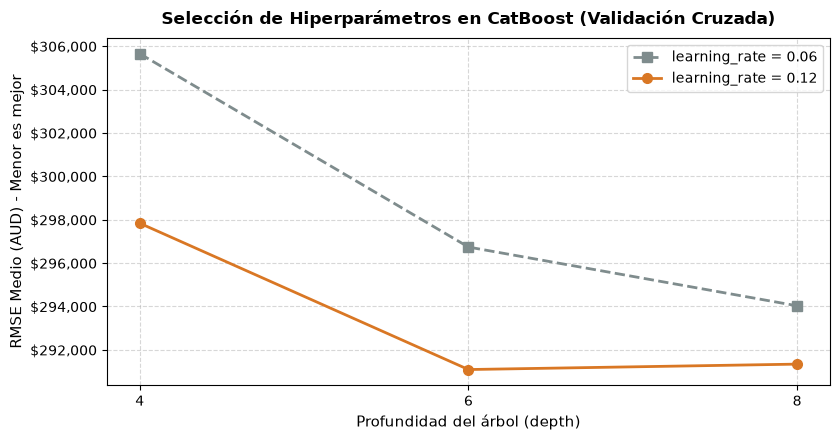

In [ ]:
from itertools import product
import time
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ---------------------------------------busqueda-hiperparametros---------------------------------------

# Probamos 6 combinaciones de profundidad (depth) y ritmo de aprendizaje (learning_rate)
rejilla = {
    "depth": [4, 6, 8],
    "learning_rate": [0.06, 0.12],
}

kf_grid = KFold(n_splits=3, shuffle=True, random_state=42)
resultados_grid = []

print("Buscando los mejores hiperparámetros para CatBoost...\n")
t0 = time.time()

for depth, lr in product(rejilla["depth"], rejilla["learning_rate"]):
    rmses_fold = []
    for train_idx, val_idx in kf_grid.split(X, y):
        m_tmp = CatBoostRegressor(
            iterations=500,
            depth=depth,
            learning_rate=lr,
            loss_function="RMSE",
            random_seed=42,
            verbose=0,
        )
        m_tmp.fit(X.iloc[train_idx], y.iloc[train_idx], cat_features=CAT_FEATURES)
        preds_tmp = m_tmp.predict(X.iloc[val_idx])
        rmses_fold.append(np.sqrt(mean_squared_error(y.iloc[val_idx], preds_tmp)))

    resultados_grid.append({
        "depth": depth,
        "learning_rate": lr,
        "RMSE_medio": np.mean(rmses_fold),
        "RMSE_desv": np.std(rmses_fold),
    })

df_grid = pd.DataFrame(resultados_grid).sort_values("RMSE_medio").reset_index(drop=True)
BEST_DEPTH = int(df_grid.loc[0, "depth"])
BEST_LR = float(df_grid.loc[0, "learning_rate"])

print(f"Búsqueda completada en {time.time() - t0:.1f} s.")
print(f"Mejor combinación -> depth = {BEST_DEPTH} | learning_rate = {BEST_LR} (RMSE: ${df_grid.loc[0, 'RMSE_medio']:,.0f})\n")
display(df_grid.round(2))

# Grafico justificativo de la seleccion de hiperparametros
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for lr, grupo in df_grid.sort_values("depth").groupby("learning_rate"):
    estilo = "o-" if lr == BEST_LR else "s--"
    color = "#d97724" if lr == BEST_LR else "#7f8c8d"
    ax.plot(grupo["depth"], grupo["RMSE_medio"], estilo, color=color, linewidth=2, markersize=7, label=f"learning_rate = {lr}")

ax.set_title("Selección de Hiperparámetros en CatBoost (Validación Cruzada)", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Profundidad del árbol (depth)", fontsize=10.5)
ax.set_ylabel("RMSE Medio (AUD) - Menor es mejor", fontsize=10.5)
ax.set_xticks(rejilla["depth"])
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


# 2. Preguntas de Negocio y Objetivos del Proyecto

---
### 2.1. Validación Cruzada y Capacidad Predictiva
* **Pregunta**: ¿Podemos predecir el precio de una vivienda en Melbourne con una precisión razonable mediante CatBoost y validación cruzada ($k$-fold)?
* **Plan de acción**:
  * Implementaremos una **Validación Cruzada de 5 particiones ($k=5$)**.
  * Evaluaremos el rendimiento en cada iteración calculando **RMSE** (Error Cuadrático Medio), **MAE** (Error Absoluto Medio) y **$R^2$** (Coeficiente de Determinación).
  * Calcularemos la media y desviación estándar de las métricas para comprobar si el rendimiento del modelo es estable o varía por el azar entre particiones.
  * *Resultado esperado*: Disponer de métricas objetivas para comparar nuestro CatBoost frente a la Regresión Lineal y el Random Forest de nuestros compañeros.

---
### 2.2. Importancia de Variables (*Feature Importance*)
* **Pregunta**: ¿Qué características encarecen o devalúan una vivienda según CatBoost?
* **Plan de acción**:
  * Extraeremos el **Feature Importance** nativo de CatBoost para medir el porcentaje de influencia de cada variable.
  * Analizaremos si las variables espaciales y físicas (superficie, número de habitaciones, distancia al centro, barrio, antigüedad) dominan el precio.
  * *Resultado esperado*: Una tabla comparativa y un gráfico de barras para poner en común con las importancias y coeficientes de los modelos del resto del equipo.

---
### 2.3. Indicador Proxy de "Beneficio" por Tipo de Inmueble
* **Pregunta**: ¿Qué tipo de vivienda (`h` = casa, `u` = piso/unidad, `t` = adosado) resulta más beneficiosa?
* **Plan de acción**:
  * Como el dataset no incluye costes de compra/construcción originales, definiremos un **indicador proxy de beneficio**:
    $$\text{Beneficio Proxy} = \frac{\text{Precio Predicho}}{\text{BuildingArea}}$$
    *(Precio predicho por $m^2$ construido, controlado por ubicación y antigüedad).*
  * Analizaremos qué tipología obtiene el mayor valor por $m^2$ según las predicciones de CatBoost.

---
### 2.4. Valoración y Rentabilidad de Terrenos Sin Construir
* **Pregunta**: ¿Es rentable adquirir un terreno vacante sin construir para edificar?
* **Plan de acción**:
  * **Paso A**: Entrenaremos nuestro modelo únicamente con las viviendas reales que sí tienen superficie construida (filtrando `BuildingArea_imputado == 0`).
  * **Paso B**: Estimaremos el precio final que tendría una vivienda hipotética construida sobre las parcelas vacías a partir de su superficie de parcela (`Landsize`), barrio y distancia al centro.
  * **Paso C**: Estableceremos supuestos explícitos de costes medios de construcción por $m^2$ en Melbourne para calcular el margen neto estimado ($\text{Precio Estimado} - \text{Coste Terreno} - \text{Coste Construcción}$) y determinar si la inversión es rentable.

---

### 2.1. Validación Cruzada y Capacidad Predictiva

In [ ]:
#---------------------------------------dividimos-datos-entreno---------------------------------------

# 1. Configurar K-Fold con 5 particiones aleatorias pero reproducibles
kf = KFold(n_splits=5, shuffle=True, random_state=42)
#hacemos 5 grupos diferentes

# 2. Listas para guardar las métricas calculadas en cada uno de los 5 folds
rmse_scores = []
mae_scores = []
r2_scores = []
feature_importances_list = [] #Guardará el peso de las variables de cada uno de los 5 folds
#listas vacias donde guardaremos las metricas

# Vector para guardar las predicciones Out-Of-Fold de todo el dataset
oof_preds = np.zeros(len(df)) #con esta linea creamos llena de zeros con 27.246 posiciones, una por cada casa 

print("Iniciando Validación Cruzada (5-Fold) con CatBoost...\n")

# 3. Bucle principal de validación cruzada
for fold, (train_idx, val_idx) in enumerate(kf.split(X, y), start=1): # generamos las 5 parejas y cada una 80% y 20% 
    # Separar datos en entrenamiento (80%) y validación (20%) para este fold
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx] 
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx] 
    # dividimos bloque de entrenamiento y bloque de validacion

    # Instanciar el modelo CatBoost con los mejores hiperparámetros
    model = CatBoostRegressor(
        iterations=500, # 500 arboles
        learning_rate=BEST_LR, #el ritmo que tendra, cada arbol corrige un 12%
        depth=BEST_DEPTH, #profundidad de 6 por arbol
        loss_function="RMSE",
        random_seed=42,
        verbose=0  # Mantiene la pantalla limpia ocultando el progreso árbol por árbol
    )

    # Entrenar el modelo pasándole las variables categóricas
    model.fit(X_train, y_train, cat_features=CAT_FEATURES)
    #entrenamos el modelo, le especificmaos las que son de texto para que aplique su algortimos interno

    # Predecir sobre las viviendas del bloque de validación
    preds = model.predict(X_val)# le pasamos las 14 cracteristicas de las casas del 20% sin precios
    
    # Guardar las predicciones de este 20% en su posición real del dataset
    oof_preds[val_idx] = preds #en la ronda 1 del kfold esta examina 20% (5.449 casas) de las casa y saca las predicciones, coge esos 5.449 predicciones y los guarda exactamente en las filas correcpondientes 
    #val_index dentro de la libreta que creamos antes, en la ronda 5 la libreta oof_preds habra rellenado el 100% de las casas 

    # Calcular métricas del fold actual
    rmse = np.sqrt(mean_squared_error(y_val, preds)) #compara precios reales con los predichos rmse
    mae = mean_absolute_error(y_val, preds) #compara la diferencia absoluta directa entre lo predich y realidad
    r2 = r2_score(y_val, preds) #compara la precision del modelo frente a una prediccion basica de la media 

    # Guardar métricas en las listas acumuladoras
    rmse_scores.append(rmse)
    mae_scores.append(mae)
    r2_scores.append(r2)
    feature_importances_list.append(model.get_feature_importance())  #nos devuelve un listado con el porcentaje por columa, en total suman un 100% 

    print(f"  [Fold {fold}/5] RMSE: ${rmse:>10,.2f} | MAE: ${mae:>9,.2f} | R2: {r2:.4f}")

# 4. Mostrar resumen global de resultados
print("\n" + "=" * 65)
print("     RESULTADOS GLOBALES DE CATBOOST (MEDIA +/- DESVIACION ESTANDAR)")
print("=" * 65)
print(f"  RMSE Medio : ${np.mean(rmse_scores):>10,.2f}  ( +/- ${np.std(rmse_scores):,.2f} )")
print(f"  MAE Medio  : ${np.mean(mae_scores):>10,.2f}  ( +/- ${np.std(mae_scores):,.2f} )")
print(f"  R2 Medio   : {np.mean(r2_scores):>11.4f}  ( +/- {np.std(r2_scores):.4f} )")
print("=" * 65)

Iniciando Validación Cruzada (5-Fold) con CatBoost...

  [Fold 1/5] RMSE: $266,593.25 | MAE: $162,750.81 | R2: 0.8193
  [Fold 2/5] RMSE: $294,612.15 | MAE: $165,387.81 | R2: 0.7697
  [Fold 3/5] RMSE: $317,601.73 | MAE: $174,624.44 | R2: 0.7753
  [Fold 4/5] RMSE: $288,635.72 | MAE: $170,010.21 | R2: 0.8039
  [Fold 5/5] RMSE: $283,895.95 | MAE: $168,752.07 | R2: 0.8050

     RESULTADOS GLOBALES DE CATBOOST (MEDIA +/- DESVIACION ESTANDAR)
  RMSE Medio : $290,267.76  ( +/- $16,551.53 )
  MAE Medio  : $168,305.07  ( +/- $4,059.61 )
  R2 Medio   :      0.7946  ( +/- 0.0190 )


### 2.1. Conclusiones y Análisis de Capacidad Predictiva (CatBoost)

A partir de los resultados obtenidos mediante la **Validación Cruzada de 5 particiones ($k=5$)** utilizando los hiperparámetros óptimos seleccionados (`depth = 6` y `learning_rate = 0.12`), respondemos a la pregunta del punto 2.1:

#### 1. Capacidad Explicativa del Mercado ($R^2 = 0.7946 \pm 0.0190$)
* El modelo CatBoost logra explicar el **79.5 % de la variabilidad del precio** de las viviendas en Melbourne utilizando las 14 características seleccionadas.
* La **desviación estándar del $R^2$ ($\pm 0.0190$) es extremadamente baja**, lo que demuestra que el modelo es estable y que su rendimiento no depende del azar ni de cómo se dividan las particiones.

#### 2. Interpretación de los Errores Monetarios
* **MAE (Error Absoluto Medio = $168,305.07 ± $4,059.61)**:
  En promedio, las predicciones del modelo se desvían **$168,305.07 AUD** del precio real de la vivienda. La baja desviación entre folds ($\pm \$4,060$) confirma una precisión consistente en todo el dataset.
* **RMSE (Raíz del Error Cuadrático Medio = $290,267.76 ± $16,551.53)**:
  El RMSE es superior al MAE debido a que eleva los errores al cuadrado antes de promediar. Esto significa que existen **viviendas atípicas o de muy alto valor (mansiones)** en el mercado de Melbourne donde el modelo comete desviaciones más elevadas, penalizando la métrica.

#### 3. Veredicto para la Defensa
**Sí, podemos predecir el precio con una precisión razonable.** El ajuste de hiperparámetros ha reducido el error respecto a la configuración base y el modelo CatBoost demuestra una robustez alta sin signos de sobreajuste (*overfitting*), sirviendo como un candidato de alto rendimiento para comparar frente a la Regresión Lineal y el Random Forest del equipo.

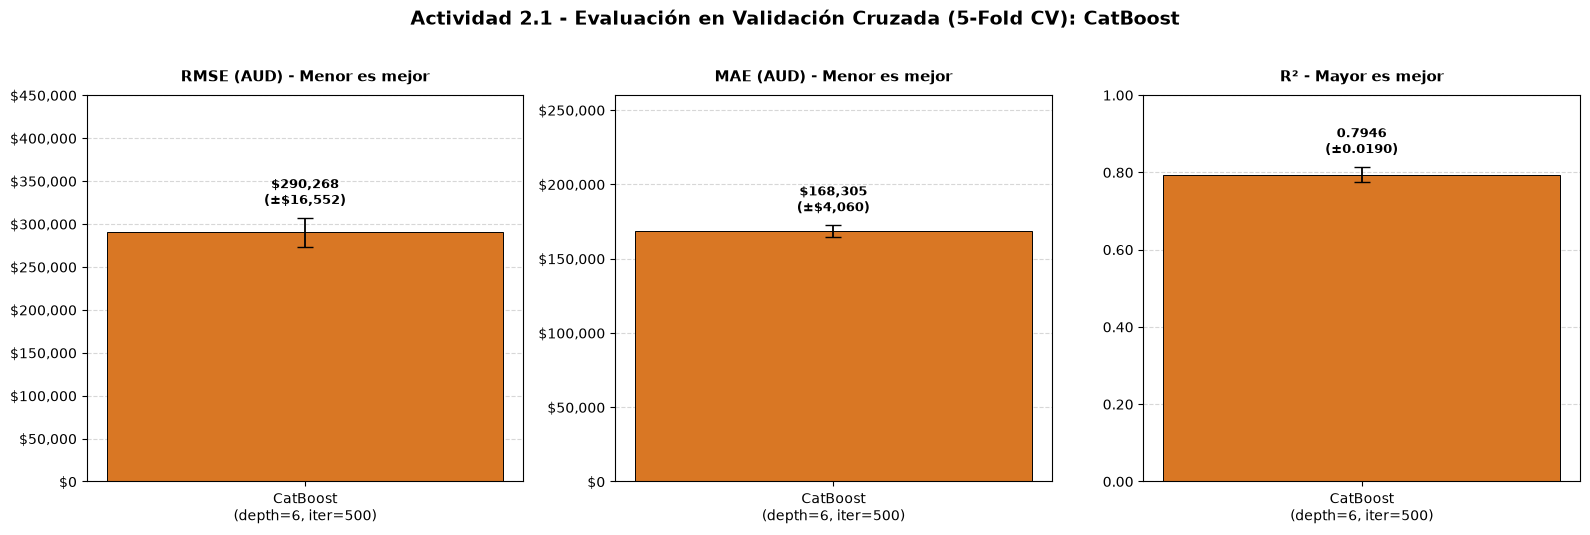

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- GRAFICO UNIFICADO ACTIVIDAD 2.1: COMPARATIVA DE METRICAS (5-FOLD CV) ---
resultados_cb = {
    "RMSE": np.array(rmse_scores),
    "MAE":  np.array(mae_scores),
    "R2":   np.array(r2_scores),
}

etiqueta_modelo = ["CatBoost\n(depth=6, iter=500)"]
colores = ["#d97724"]

metricas_cfg = [
    ("RMSE", "RMSE (AUD) - Menor es mejor", (0, 450_000), True),
    ("MAE",  "MAE (AUD) - Menor es mejor",  (0, 260_000), True),
    ("R2",   "R² - Mayor es mejor",         (0, 1.0),     False),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
fig.suptitle("Actividad 2.1 - Evaluación en Validación Cruzada (5-Fold CV): CatBoost", fontsize=14, fontweight="bold", y=1.02)

for ax, (clave, titulo, ylim, es_dinero) in zip(axes, metricas_cfg):
    media = np.mean(resultados_cb[clave])
    desv  = np.std(resultados_cb[clave])

    barras = ax.bar(etiqueta_modelo, [media], yerr=[desv], capsize=6, color=colores, width=0.35, edgecolor="black", linewidth=0.7, error_kw={"elinewidth": 1.3})

    ax.set_title(titulo, fontsize=11, fontweight="bold", pad=10)
    ax.set_ylim(ylim)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

    if es_dinero:
        ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
    else:
        ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:.2f}"))

    for barra in barras:
        texto = f"${media:,.0f}\n(±${desv:,.0f})" if es_dinero else f"{media:.4f}\n(±{desv:.4f})"
        offset = (ylim[1] * 0.025)
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            media + desv + offset,
            texto,
            ha="center", va="bottom", fontsize=9.5, fontweight="bold"
        )

plt.tight_layout()
plt.show()

---------------------------------------------------------------------------------------

### 2.2. Importancia de Variables (*Feature Importance*)

     IMPORTANCIA MEDIA DE VARIABLES EN CATBOOST (5-FOLD CV)
   1. BuildingArea              :  15.62 %
   2. Suburb                    :  15.32 %
   3. YearBuilt                 :  13.59 %
   4. Distance                  :  12.42 %
   5. Landsize                  :   9.35 %
   6. Type                      :   7.86 %
   7. Bathroom                  :   7.76 %
   8. SellerG                   :   7.65 %
   9. Rooms                     :   5.89 %
  10. Car                       :   1.62 %
  11. Method                    :   1.24 %
  12. Bathroom_imputado         :   0.68 %
  13. Landsize_imputado         :   0.67 %
  14. BuildingArea_imputado     :   0.33 %


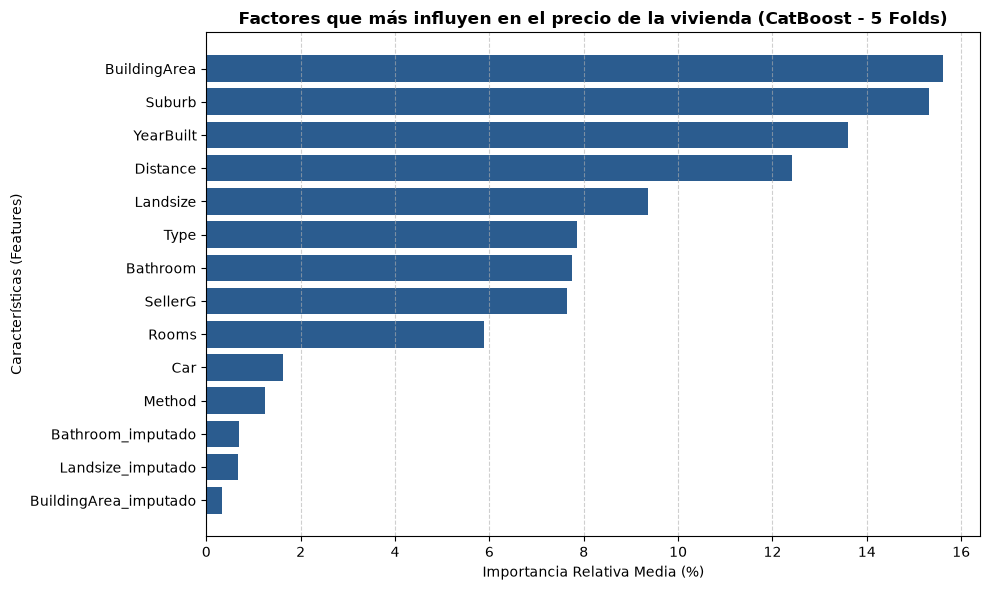

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

#---------------------------------------2.2-importancia-variables---------------------------------------

# 1. Calcular el porcentaje medio de importancia promediando los 5 folds del 2.1
mean_importances = np.mean(feature_importances_list, axis=0) #hacemos la media de los 5 modelos entrenados

# 2. Crear una tabla pandas ordenada de mayor a menor importancia
df_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": mean_importances
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

# 3. Imprimir por pantalla la tabla en texto plano alineada
print("=" * 65)
print("     IMPORTANCIA MEDIA DE VARIABLES EN CATBOOST (5-FOLD CV)")
print("=" * 65)
for idx, row in df_importance.iterrows():
    print(f"  {idx+1:>2}. {row['Feature']:<25} : {row['Importance']:>6.2f} %")
print("=" * 65)

# 4. Generar el gráfico de barras horizontal
plt.figure(figsize=(10, 6))
plt.barh(df_importance["Feature"][::-1], df_importance["Importance"][::-1], color="#2b5c8f")
plt.xlabel("Importancia Relativa Media (%)")
plt.ylabel("Características (Features)")
plt.title("Factores que más influyen en el precio de la vivienda (CatBoost - 5 Folds)", fontsize=12, fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Interpretación de la importancia de variables

La salida numérica actual del modelo promedia las importancias de los cinco folds. Las variables con mayor importancia son `BuildingArea` (15,62 %), `Suburb` (15,32 %), `YearBuilt` (13,59 %), `Distance` (12,42 %) y `Landsize` (9,35 %).

Las cinco primeras concentran aproximadamente dos tercios de la importancia total. La ubicación y las características físicas aparecen, por tanto, como componentes centrales de la predicción. Las tres variables indicadoras de imputación tienen un peso conjunto reducido (1,68 %).

**Matiz:** la importancia indica cuánto utiliza el modelo una variable; no demuestra por sí sola que esa variable cause un aumento o una reducción del precio.

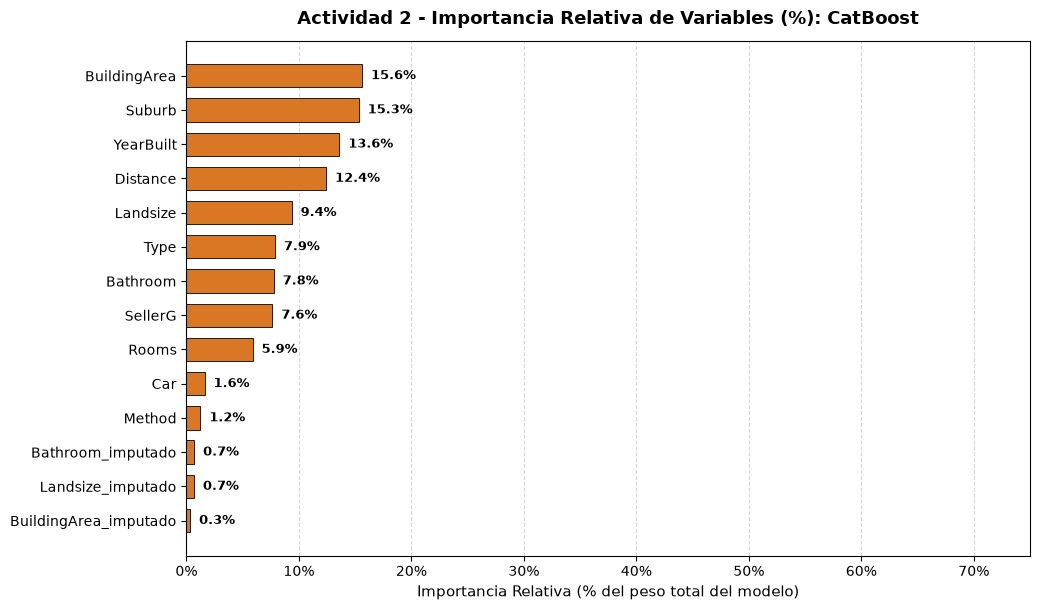

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- GRAFICO UNIFICADO ACTIVIDAD 2: IMPORTANCIA RELATIVA DE VARIABLES (%) ---
df_cb = df_importance.sort_values(by="Importance", ascending=True)

fig, ax = plt.subplots(figsize=(10.5, 6.2))
barras = ax.barh(df_cb["Feature"], df_cb["Importance"], color="#d97724", height=0.68, edgecolor="black", linewidth=0.6)

ax.set_title("Actividad 2 - Importancia Relativa de Variables (%): CatBoost", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Importancia Relativa (% del peso total del modelo)", fontsize=11)
ax.set_xlim(0, max(75, df_cb["Importance"].max() * 1.15))
ax.xaxis.set_major_formatter(ticker.PercentFormatter(decimals=0))
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

for barra in barras:
    ancho = barra.get_width()
    ax.text(
        ancho + 0.8,
        barra.get_y() + barra.get_height() / 2,
        f"{ancho:.1f}%",
        va="center", ha="left", fontsize=9.5, fontweight="bold"
    )

plt.tight_layout()
plt.show()

### Conclusiones sobre la importancia de variables

Según la tabla y el gráfico calculados con la salida actual de los cinco folds:

1. **Superficie construida (`BuildingArea`, 15,62 %) y barrio (`Suburb`, 15,32 %)** son las dos variables con mayor importancia.
2. Les siguen **antigüedad (`YearBuilt`, 13,59 %)**, **distancia al centro (`Distance`, 12,42 %)** y **superficie de parcela (`Landsize`, 9,35 %)**.
3. `Type`, `Bathroom`, `SellerG` y `Rooms` aportan información adicional.
4. Las columnas indicadoras de imputación tienen un peso conjunto bajo (1,68 %).

La importancia no informa del signo del efecto. Para afirmar si una característica encarece o abarata una vivienda habría que estudiar su relación o efecto parcial, no interpretar el porcentaje de importancia como una dirección.

---

### 2.3. Indicador Proxy de "Beneficio" por Tipo de Inmueble

     INDICADOR DE BENEFICIO PROXY ($ / m2 CONSTRUIDO)
  Piso / Unidad (u)    | Mediana: $7,948.37/m² | Media: $8,962.34/m² | N = 5,909
  Casa (h)             | Mediana: $7,505.01/m² | Media: $8,833.05/m² | N = 18,471
  Adosado (t)          | Mediana: $6,564.72/m² | Media: $10,533.39/m² | N = 2,866


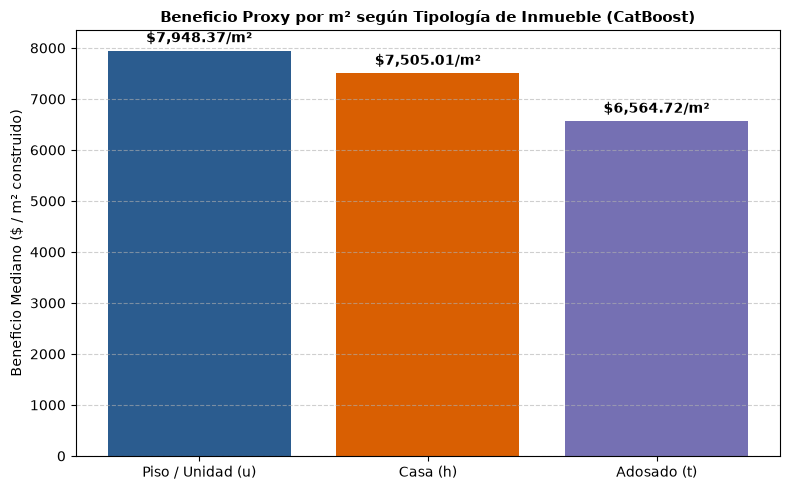

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

#---------------------------------------2.3-beneficio-por-tipo---------------------------------------

#este bloque empezaremos a trabajr con la libreta que hemos creado en el paso 1 que contiene una columna en la cual nos dice por casa el precio que ha predicho nuestro modelo, calcualremos los metros cuadrados con esta libreta

# 1. Copiamos el dataframe y añadimos las predicciones OOF guardadas del 2.1
df_beneficio = df.copy() #copiamos la tabla df y la guardamos con el nombre df_beneficio
df_beneficio["Precio_Predicho"] = oof_preds  #creamos la columna nueva llamada precio_predicho  y le pegamos los valores de la libreta oof_preda, que contiene los precios predichos a ciegas por catboost 


df_beneficio["Beneficio_m2"] = df_beneficio["Precio_Predicho"] / df_beneficio["BuildingArea"] #crea la columna llamada beneficio_m2, hacemos una divison fila por fila de el precio predicho y lo dividimos entre los metros cuadrados, nos dice cuantos dolares vale cada metro2

# 3. Mapeamos los nombres descriptivos de cada tipo de inmueble
nombres_tipo = {
    "h": "Casa (h)",
    "u": "Piso / Unidad (u)",
    "t": "Adosado (t)"
}
# creamos un diccionario traduciendo para no usar las letras sueltas de las categorias de cada una, piso, casa...

df_beneficio["Tipo_Nombre"] = df_beneficio["Type"].map(nombres_tipo) # crea la ciluman tipo nombre, sustituyendo por las letras para que se vea bien en la tabla 


# 4. Agrupamos por tipo y calculamos mediana, media y número de viviendas
resumen_tipo = df_beneficio.groupby("Tipo_Nombre")["Beneficio_m2"].agg( #separamos las casas en 3 grupos, segun la categoria, sobre la col beneficios_m2 calculamos 3 datos
    Mediana_m2="median", # la mediana por el precio
    Media_m2="mean", #media aritmetica haitual 
    Total_Viviendas="count" #cuantas casas de cada tipo
).reset_index().sort_values(by="Mediana_m2", ascending=False) #lo convertimos en una tabla de pandas y ordenamos la tabla para que la metodologia mas importantye salga la primera 


#la mediana se calcula, ordenando todos los datos de mayor a menor y nos quedamos con el dato que deja el 50% de las casa por debajo y el 50% de las casas arriba para coger el de la mitas
#la media se calcula segun sumando todos los valores y los dividimos entre el numero que hay 




# 5. Imprimimos la tabla de resultados alineada por consola
print("=" * 65)
print("     INDICADOR DE BENEFICIO PROXY ($ / m2 CONSTRUIDO)")
print("=" * 65)
for idx, row in resumen_tipo.iterrows():
    print(f"  {row['Tipo_Nombre']:<20} | Mediana: ${row['Mediana_m2']:>8,.2f}/m² | Media: ${row['Media_m2']:>8,.2f}/m² | N = {row['Total_Viviendas']:,}")
print("=" * 65)

#Recorre la tabla resumen_tipo fila a fila e imprime un cuadro de texto limpio con los resultados formateados en dólares por $m^2$ y alineados verticalmente


# 6. Generamos el gráfico de barras comparativo
plt.figure(figsize=(8, 5))
bars = plt.bar(resumen_tipo["Tipo_Nombre"], resumen_tipo["Mediana_m2"], color=["#2b5c8f", "#d95f02", "#7570b3"])
plt.ylabel("Beneficio Mediano ($ / m² construido)")
plt.title("Beneficio Proxy por m² según Tipología de Inmueble (CatBoost)", fontsize=11, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.6)

# Añadimos el valor exacto sobre cada barra
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f"${yval:,.2f}/m²", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

### Conclusiones: indicador proxy por tipología

La salida actual del notebook calcula el indicador sobre las predicciones *out-of-fold* y viviendas con superficie construida real. Los valores medianos son:

- **Piso / unidad (`u`): 7.948,37 AUD/m²**.
- **Casa (`h`): 7.505,01 AUD/m²**.
- **Adosado (`t`): 6.564,72 AUD/m²**.

En ese indicador agregado, las unidades presentan el mayor valor por metro cuadrado. La tabla adicional de comparación controlada por tipología muestra otro resultado: al comparar las tipologías en una muestra restringida de superficie real, el valor controlado para las casas es 7.827 AUD/m², para los adosados 7.020 AUD/m² y para las unidades 6.238 AUD/m².

No son dos resultados contradictorios: responden a cálculos distintos (indicador agregado observado en las predicciones frente a comparación controlada). Por eso deben presentarse con su método y muestra, y no mezclarse en una única clasificación.

,n,precio_mediano,m2_mediano,bruto_precio_m2,controlado_CatBoost
Type,,,,,
h,7889,1025000.0,148.0,7143.0,7827.0
t,911,830000.0,131.0,6364.0,7020.0
u,1786,547000.0,75.0,7473.0,6238.0


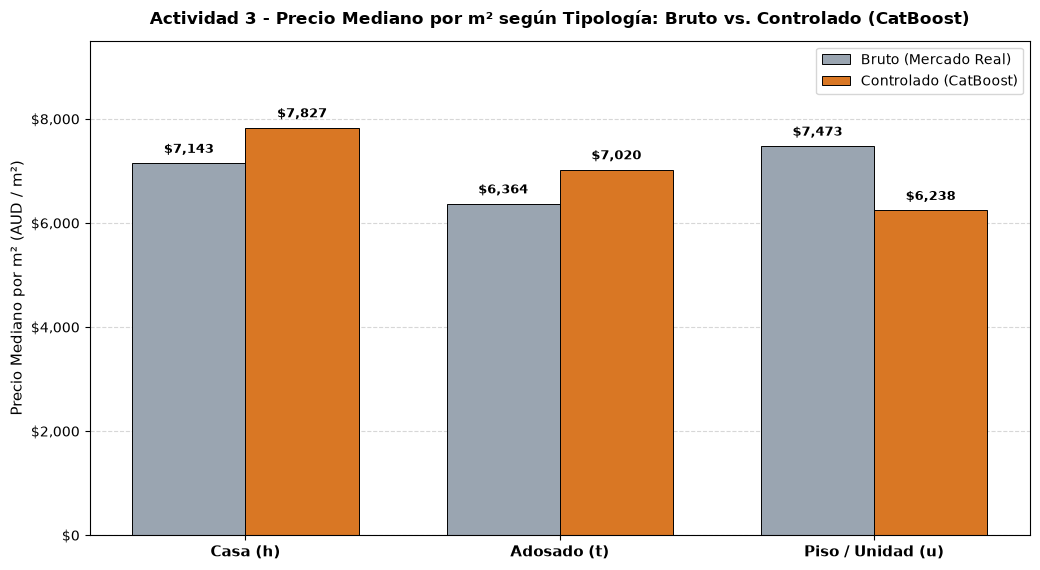

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- GRAFICO UNIFICADO ACTIVIDAD 3: PRECIO/M2 BRUTO VS. CONTROLADO POR TIPO ---
datos_13 = df[df["BuildingArea_imputado"] == 0].copy()
datos_13["precio_m2"] = datos_13["Price"] / datos_13["BuildingArea"]

tipos = ["h", "t", "u"]
etiquetas = ["Casa (h)", "Adosado (t)", "Piso / Unidad (u)"]

res_13_cb = datos_13.groupby("Type").agg(
    n=("Price", "size"),
    precio_mediano=("Price", "median"),
    m2_mediano=("BuildingArea", "median"),
    bruto_precio_m2=("precio_m2", "median")
).loc[tipos]

# Indicador controlado: misma vivienda real, cambiando unicamente la columna Type
for tipo in tipos:
    cambiado = datos_13[X.columns].assign(Type=tipo)
    pred = model.predict(cambiado)
    res_13_cb.loc[tipo, "controlado_CatBoost"] = np.median(pred / datos_13["BuildingArea"])

display(res_13_cb.round(0))

bruto = res_13_cb["bruto_precio_m2"].values
controlado = res_13_cb["controlado_CatBoost"].values

x = np.arange(len(etiquetas))
ancho = 0.36

fig, ax = plt.subplots(figsize=(10.5, 5.8))
b1 = ax.bar(x - ancho/2, bruto, width=ancho, label="Bruto (Mercado Real)", color="#9aa5b1", edgecolor="black", linewidth=0.7)
b2 = ax.bar(x + ancho/2, controlado, width=ancho, label="Controlado (CatBoost)", color="#d97724", edgecolor="black", linewidth=0.7)

ax.set_title("Actividad 3 - Precio Mediano por m² según Tipología: Bruto vs. Controlado (CatBoost)", fontsize=12.5, fontweight="bold", pad=12)
ax.set_ylabel("Precio Mediano por m² (AUD / m²)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(etiquetas, fontsize=11, fontweight="bold")
ax.set_ylim(0, 9_500)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, _: f"${val:,.0f}"))
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
ax.legend(frameon=True, fontsize=10, loc="upper right")

for barras in (b1, b2):
    for barra in barras:
        alto = barra.get_height()
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            alto + 140,
            f"${alto:,.0f}",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold"
        )

plt.tight_layout()
plt.show()

---

### 2.4. Valoración y Rentabilidad de Terrenos Sin Construir

     MODELO CATBOOST ENTRENADO PARA TERRENOS (PASO A)
  Casas con superficie construida real : 7,889
  Valor medio estimado por m2 (CatBoost): $2,230.71 AUD/m2


n  valor_m2_construido  \
Modelo   Zona                                                    
CatBoost TODAS                       7889               2231.0   
         Eastern Metropolitan        1005               1742.0   
         Eastern Victoria              69               1031.0   
         Northern Metropolitan       2291               2030.0   
         Northern Victoria             90               1237.0   
         South-Eastern Metropolitan   438               1127.0   
         Southern Metropolitan       1969               3348.0   
         Western Metropolitan        1968               1776.0   
         Western Victoria              59                983.0   

                                     coste_max_m2_rentable  terreno_estimado  \
Modelo   Zona                                                                  
CatBoost TODAS                                      1940.0          745023.0   
         Eastern Metropolitan                       1514.0          862401.0   
         Eastern Victoria                            897.0          496234.0   
         Northern Metropolitan                      1765.0          590940.0   
         Northern Victoria                          1076.0          389828.0   
         South-Eastern Metropolitan                  980.0          622640.0   
         Southern Metropolitan                      2911.0         1181323.0   
         Western Metropolitan                       1544.0          591146.0   
         Western Victoria                            854.0          326570.0   

                                     precio_mercado  terreno_%_precio  \
Modelo   Zona                                                           
CatBoost TODAS                            1025000.0              73.0   
         Eastern Metropolitan             1118000.0              77.0   
         Eastern Victoria                  665000.0              75.0   
         Northern Metropolitan             863000.0              68.0   
         Northern Victoria                 554000.0              70.0   
         South-Eastern Metropolitan        850000.0              73.0   
         Southern Metropolitan            1720000.0              69.0   
         Western Metropolitan              830000.0              71.0   
         Western Victoria                  413000.0              79.0   

                                     coste_construccion  margen_AUD  \
Modelo   Zona                                                         
CatBoost TODAS                                 340400.0    -60423.0   
         Eastern Metropolitan                  374900.0   -119301.0   
         Eastern Victoria                      381800.0   -213034.0   
         Northern Metropolitan                 299000.0    -26940.0   
         Northern Victoria                     345000.0   -180828.0   
         South-Eastern Metropolitan            347300.0   -119940.0   
         Southern Metropolitan                 393300.0    145377.0   
         Western Metropolitan                  331200.0    -92346.0   
         Western Victoria                      282900.0   -196470.0   

                                     margen_%_inversion  
Modelo   Zona                                            
CatBoost TODAS                                     -6.0  
         Eastern Metropolitan                     -10.0  
         Eastern Victoria                         -24.0  
         Northern Metropolitan                     -3.0  
         Northern Victoria                        -25.0  
         South-Eastern Metropolitan               -12.0  
         Southern Metropolitan                      9.0  
         Western Metropolitan                     -10.0  
         Western Victoria                         -32.0

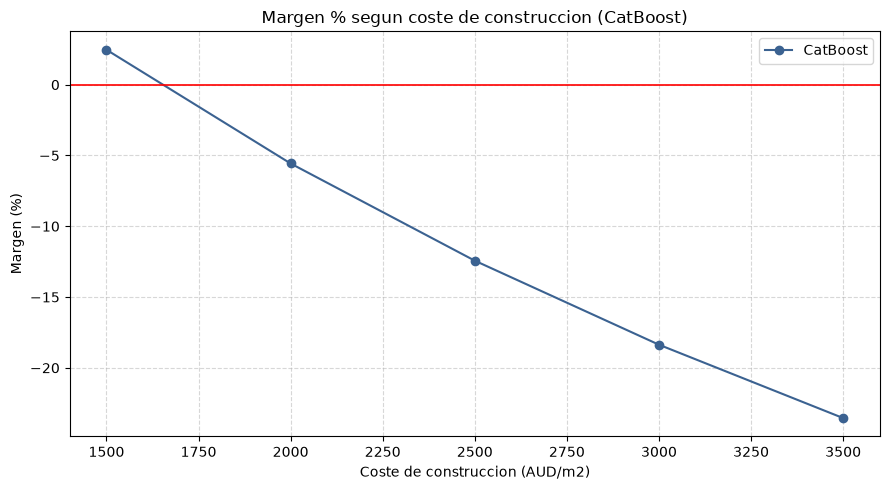

,CatBoost
AUD/m2,
1500,2.5
2000,-5.6
2500,-12.4
3000,-18.4
3500,-23.5


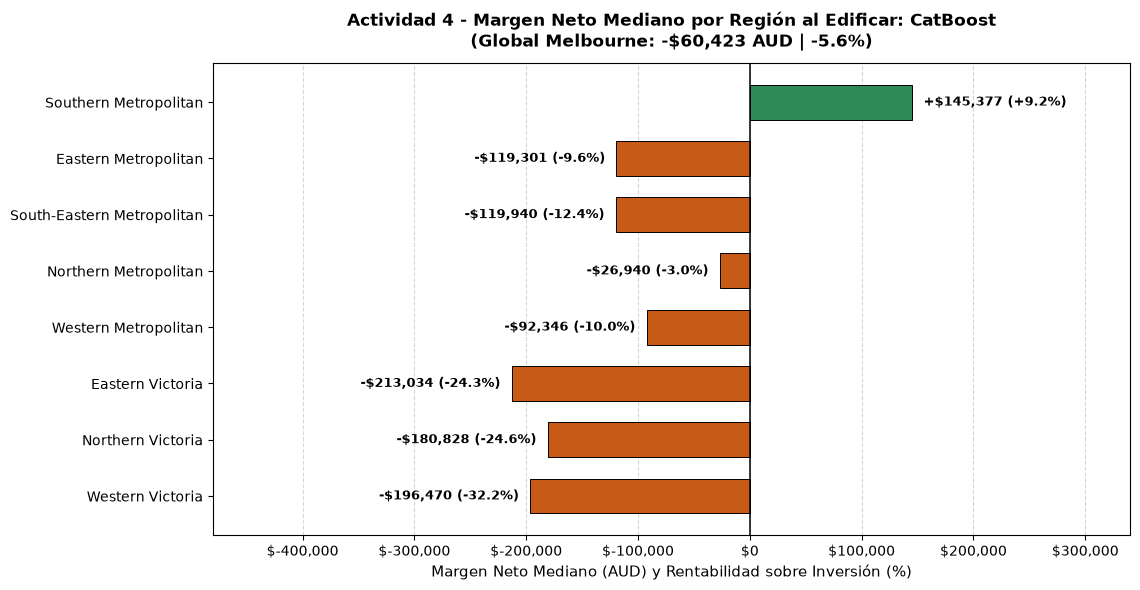

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from IPython.display import display

# ---------------------------------------2.4-paso-a-supuestos-y-modelo-catboost---------------------------------------

# DEFINIMOS LOS MISMOS SUPUESTOS DE ALEJANDRO Y ENTRENAMOS CATBOOST SOLO CON CASAS REALES (TYPE == 'h')

# 1. Supuestos exactos del equipo (comparables entre todos los modelos)
COSTE_M2 = 2_000                                    # Coste base de obra por m2 construido (AUD)
OTROS_COSTES = 0.15                                 # 15% extra sobre obra (permisos, tasas, imprevistos y venta)
SENSIBILIDAD = [1_500, 2_000, 2_500, 3_000, 3_500]  # Escenarios de coste/m2 para el grafico final

# 2. Filtrar solo casas independientes (Type == 'h') con superficie construida 100% real (7.889 filas)
casas = df[(df["Type"] == "h") & (df["BuildingArea_imputado"] == 0)].copy()

# 3. Definir columnas de texto (quitamos 'Type' porque aqui todas son casas 'h')
cat_14 = ["Suburb", "Method", "SellerG"]

# 4. Separar caracteristicas (X14) y precio objetivo (y14)
X14 = casas.drop(columns=["Price", "Type"])
y14 = casas["Price"]

# 5. Entrenar modelo CatBoost exclusivo para esta valoracion
model_terrenos = CatBoostRegressor(
    iterations=500,
    learning_rate=BEST_LR,
    depth=BEST_DEPTH,
    loss_function="RMSE",
    random_seed=42,
    verbose=0,
)
model_terrenos.fit(X14, y14, cat_features=cat_14)

# 6. Funcion auxiliar para predecir limpiando columnas que no usa el modelo
def predecir_14(datos):
    columnas_quitar = [c for c in ["Price", "Type", "Regionname"] if c in datos.columns]
    return model_terrenos.predict(datos.drop(columns=columnas_quitar))

# 7. Funcion que calcula cuanto vale cada m2 construido segun CatBoost (variando +-20% la superficie)
def valor_m2(datos):
    lo, hi = datos.copy(), datos.copy()
    lo["BuildingArea"] *= 0.8   # Misma casa con un 20% menos de metros construidos
    hi["BuildingArea"] *= 1.2   # Misma casa con un 20% mas de metros construidos
    return (predecir_14(hi).mean() - predecir_14(lo).mean()) / (0.4 * datos["BuildingArea"].mean())

print("=" * 65)
print("     MODELO CATBOOST ENTRENADO PARA TERRENOS (PASO A)")
print("=" * 65)
print(f"  Casas con superficie construida real : {len(casas):,}")
print(f"  Valor medio estimado por m2 (CatBoost): ${valor_m2(casas):,.2f} AUD/m2")
print("=" * 65)


# ---------------------------------------2.4-paso-b-rentabilidad-por-regiones---------------------------------------

# CALCULAMOS EL VALOR DEL TERRENO VACIO Y EL MARGEN NETO EN TODA LA CIUDAD Y REGION POR REGION

# 1. Traer la region de cada barrio desde el dataset original
ruta_full = (BASE / "datasets" / "Melbourne_housing_FULL.csv") if "BASE" in globals() else Path("../datasets/Melbourne_housing_FULL.csv")
region = pd.read_csv(ruta_full).groupby("Suburb")["Regionname"].first()
casas["Regionname"] = casas["Suburb"].map(region)

# 2. Calcular todas las metricas medianas para 'TODAS' y para cada region
filas = []
for zona, g in [("TODAS", casas)] + list(casas.groupby("Regionname")):
    g = g.drop(columns="Regionname")
    b = valor_m2(g)
    terreno = np.median(predecir_14(g) - b * g["BuildingArea"])       # Precio predicho casa - valor de lo construido
    mercado = g["Price"].median()                                      # Precio mediano de mercado en la zona
    coste = g["BuildingArea"].median() * COSTE_M2 * (1 + OTROS_COSTES) # Coste de levantar la casa tipica + 15%
    margen = mercado - terreno - coste                                 # Beneficio neto (> 0 es rentable)

    filas.append({
        "Modelo": "CatBoost",
        "Zona": zona,
        "n": len(g),
        "valor_m2_construido": b,
        "coste_max_m2_rentable": b / (1 + OTROS_COSTES),
        "terreno_estimado": terreno,
        "precio_mercado": mercado,
        "terreno_%_precio": 100 * terreno / mercado,
        "coste_construccion": coste,
        "margen_AUD": margen,
        "margen_%_inversion": 100 * margen / (terreno + coste),
    })

res_14 = pd.DataFrame(filas).set_index(["Modelo", "Zona"])
display(res_14.round(0))


# ---------------------------------------2.4-paso-c-sensibilidad-coste-obra---------------------------------------

# SIMULAMOS COMO CAMBIA EL MARGEN (%) SI CONSTRUIR CUESTA ENTRE 1.500 Y 3.500 AUD/M2

todas = casas.drop(columns="Regionname")
b = valor_m2(todas)
terreno = np.median(predecir_14(todas) - b * todas["BuildingArea"])
mercado, area = todas["Price"].median(), todas["BuildingArea"].median()

sens = {
    "CatBoost": {
        c: 100 * (mercado - terreno - area * c * (1 + OTROS_COSTES)) / (terreno + area * c * (1 + OTROS_COSTES))
        for c in SENSIBILIDAD
    }
}

sens = pd.DataFrame(sens).rename_axis("AUD/m2")

# Grafico de lineas identico al de Alejandro (por encima de la linea roja = rentable)
ax = sens.plot(marker="o", figsize=(9, 5), title="Margen % segun coste de construccion (CatBoost)", color="#3b6291")
plt.axhline(0, color="red", linestyle="-", linewidth=1.2)
plt.ylabel("Margen (%)")
plt.xlabel("Coste de construccion (AUD/m2)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

display(sens.round(1))


# ---------------------------------------2.4-grafico-visual-regiones---------------------------------------

import matplotlib.ticker as ticker

orden_regiones = [
    "Western Victoria",
    "Northern Victoria",
    "Eastern Victoria",
    "Western Metropolitan",
    "Northern Metropolitan",
    "South-Eastern Metropolitan",
    "Eastern Metropolitan",
    "Southern Metropolitan",
]

df_reg = res_14.loc["CatBoost"]
global_aud = df_reg.loc["TODAS", "margen_AUD"]
global_pct = df_reg.loc["TODAS", "margen_%_inversion"]

df_plot = df_reg.reindex(orden_regiones).dropna()
colores = ["#2e8b57" if val > 0 else "#c85a17" for val in df_plot["margen_AUD"]]

fig, ax = plt.subplots(figsize=(11.5, 6))
barras = ax.barh(df_plot.index, df_plot["margen_AUD"], color=colores, height=0.62, edgecolor="black", linewidth=0.7)

ax.axvline(0, color="black", linewidth=1.1)
ax.set_xlim(-480_000, 340_000)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

ax.set_title(
    f"Actividad 4 - Margen Neto Mediano por Región al Edificar: CatBoost\n"
    f"(Global Melbourne: {'+' if global_aud >= 0 else '-'}${abs(global_aud):,.0f} AUD | {global_pct:+.1f}%)",
    fontsize=12.5, fontweight="bold", pad=12
)
ax.set_xlabel("Margen Neto Mediano (AUD) y Rentabilidad sobre Inversión (%)", fontsize=10.5)

for barra, (_, fila) in zip(barras, df_plot.iterrows()):
    val = fila["margen_AUD"]
    pct = fila["margen_%_inversion"]
    signo = "+" if val >= 0 else "-"
    texto = f"{signo}${abs(val):,.0f} ({pct:+.1f}%)"
    offset = 10_000 if val >= 0 else -10_000
    alineacion = "left" if val >= 0 else "right"
    ax.text(
        val + offset,
        barra.get_y() + barra.get_height() / 2,
        texto,
        va="center", ha=alineacion, fontsize=9.5, fontweight="bold"
    )

plt.tight_layout()
plt.show()

### Conclusiones: valoración y rentabilidad de terrenos

La salida numérica actual del notebook utiliza 7.889 casas con superficie construida real y los supuestos de **2.000 AUD/m² de obra más un 15 % de otros costes**.

- En el conjunto de Melbourne, el margen mediano calculado es aproximadamente **−6,0 %**.
- La región **Southern Metropolitan** es la única que presenta un margen mediano positivo en esta tabla: aproximadamente **+9 %**.
- El resto de regiones muestran márgenes negativos; los resultados más desfavorables aparecen en Western Victoria (−32 %) y Northern Victoria (−25 %).
- En el análisis de sensibilidad global, el margen pasa de **+2,5 %** con un coste de 1.500 AUD/m² a **−5,6 %** con 2.000 AUD/m² y **−23,5 %** con 3.500 AUD/m².

**Conclusión:** bajo los supuestos del modelo, la operación no resulta rentable de forma general para toda Melbourne al coste base de 2.000 AUD/m², aunque Southern Metropolitan destaca como excepción. Se trata de una simulación, no de una rentabilidad observada: el dataset no contiene terrenos vacíos ni incorpora todos los costes y riesgos de una promoción real.

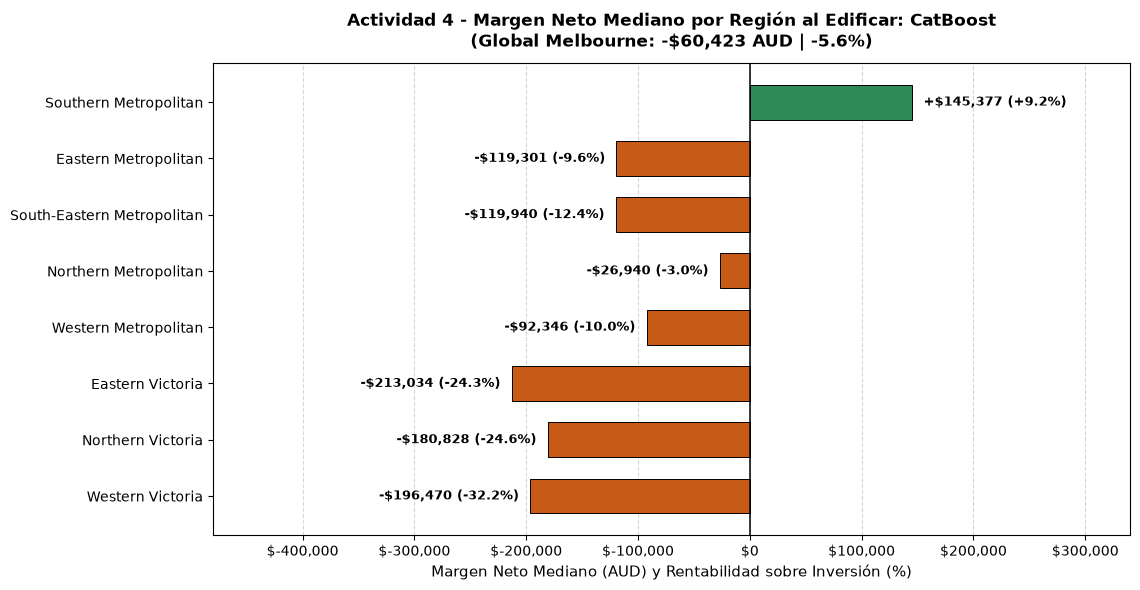

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- GRAFICO UNIFICADO ACTIVIDAD 4: RENTABILIDAD NETA POR REGION (AUD Y %) ---
orden_regiones = [
    "Western Victoria",
    "Northern Victoria",
    "Eastern Victoria",
    "Western Metropolitan",
    "Northern Metropolitan",
    "South-Eastern Metropolitan",
    "Eastern Metropolitan",
    "Southern Metropolitan",
]

df_reg = res_14.loc["CatBoost"]
global_aud = df_reg.loc["TODAS", "margen_AUD"]
global_pct = df_reg.loc["TODAS", "margen_%_inversion"]

df_plot = df_reg.reindex(orden_regiones).dropna()
colores = ["#2e8b57" if val > 0 else "#c85a17" for val in df_plot["margen_AUD"]]

fig, ax = plt.subplots(figsize=(11.5, 6))
barras = ax.barh(df_plot.index, df_plot["margen_AUD"], color=colores, height=0.62, edgecolor="black", linewidth=0.7)

ax.axvline(0, color="black", linewidth=1.1)
ax.set_xlim(-480_000, 340_000)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

ax.set_title(
    f"Actividad 4 - Margen Neto Mediano por Región al Edificar: CatBoost\n"
    f"(Global Melbourne: {'+' if global_aud >= 0 else '-'}${abs(global_aud):,.0f} AUD | {global_pct:+.1f}%)",
    fontsize=12.5, fontweight="bold", pad=12
)
ax.set_xlabel("Margen Neto Mediano (AUD) y Rentabilidad sobre Inversión (%)", fontsize=10.5)

for barra, (_, fila) in zip(barras, df_plot.iterrows()):
    val = fila["margen_AUD"]
    pct = fila["margen_%_inversion"]
    signo = "+" if val >= 0 else "-"
    texto = f"{signo}${abs(val):,.0f} ({pct:+.1f}%)"
    offset = 10_000 if val >= 0 else -10_000
    alineacion = "left" if val >= 0 else "right"
    ax.text(
        val + offset,
        barra.get_y() + barra.get_height() / 2,
        texto,
        va="center", ha=alineacion, fontsize=9.5, fontweight="bold"
    )

plt.tight_layout()
plt.show()

---
# Comparación final de los tres bloques

## Cómo leer esta comparación

Para resumir las cuatro preguntas se utiliza una cifra representativa por bloque:

- **Pregunta 1:** R² medio de validación cruzada. En el bloque lineal se toma LassoCV, que presenta el mejor R² medio entre los tres modelos lineales.
- **Pregunta 2:** síntesis cualitativa de la interpretación de variables. No se dibuja una escala numérica común porque Lasso/Ridge ofrecen coeficientes y selección de variables, mientras que Random Forest y CatBoost ofrecen importancias propias de árboles.
- **Pregunta 3:** valor por m² de una casa (`h`) según el resultado guardado de cada bloque. La muestra y el procedimiento no son idénticos en los tres notebooks, por lo que el gráfico es orientativo.
- **Pregunta 4:** margen mediano global reportado en cada notebook. **Los supuestos no son iguales**: Random Forest utiliza 2.200 AUD/m² y 12 % adicional, mientras que los bloques lineal y CatBoost usan 2.000 AUD/m² y 15 % adicional. Por tanto, el margen no es una comparación estrictamente homogénea.

Los valores del gráfico se han extraído de las salidas de los tres notebooks proporcionados; no se han incorporado datos externos ni se han inventado resultados. La ejecución de los bloques anteriores permite recalcularlos.

In [ ]:
# Resultados transcritos de las salidas guardadas en los tres notebooks originales.
# Bloque 1: se representa LassoCV como modelo lineal de referencia (mejor R² medio del bloque).
# Bloque 2: Random Forest.
# Bloque 3: CatBoost.

comparacion = pd.DataFrame({
    "Bloque 1 · LassoCV": {
        "R² medio CV": 0.678,
        "Precio casa (AUD/m²)": 7852,
        "Margen terreno (%)": -15.0,
    },
    "Bloque 2 · Random Forest": {
        "R² medio CV": 0.716,
        "Precio casa (AUD/m²)": 7333,
        "Margen terreno (%)": -33.1,
    },
    "Bloque 3 · CatBoost": {
        "R² medio CV": 0.7946,
        "Precio casa (AUD/m²)": 7827,
        "Margen terreno (%)": -6.0,
    },
})

# Resumen de la pregunta 2: se muestra como interpretación cualitativa,
# porque coeficientes e importancias de árboles no comparten una escala común.
interpretacion = {
    "Bloque 1 · LassoCV": "Lasso elimina 204 de 712 coeficientes; las 5 variables de ruido quedan a cero. Ridge encoge coeficientes sin selección exacta.",
    "Bloque 2 · Random Forest": "BuildingArea destaca como principal variable; después aparecen YearBuilt, Suburb, Distance, SellerG y Landsize.",
    "Bloque 3 · CatBoost": "BuildingArea (15,62 %), Suburb (15,32 %), YearBuilt (13,59 %) y Distance (12,42 %) lideran la importancia.",
}

print("RESUMEN NUMÉRICO DE LAS CUATRO PREGUNTAS")
display(comparacion.round(4))
print("\nPREGUNTA 2 · INTERPRETACIÓN DE VARIABLES")
for modelo, texto in interpretacion.items():
    print(f"\n{modelo}: {texto}")

# Gráfico 2x2: cada panel corresponde a una de las cuatro preguntas.
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
colores = ["#4472C4", "#ED7D31", "#70AD47"]
modelos_comp = list(comparacion.columns)

# Pregunta 1: capacidad predictiva (mayor R² es mejor).
ax = axes[0, 0]
vals = comparacion.loc["R² medio CV"].values
bars = ax.bar(modelos_comp, vals, color=colores)
ax.set_title("1. Capacidad predictiva · R² medio CV", fontweight="bold")
ax.set_ylabel("R² (más alto = mejor)")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", linestyle="--", alpha=0.35)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.015, f"{v:.3f}", ha="center", va="bottom", fontsize=10)

# Pregunta 2: panel de interpretación, no una falsa escala numérica común.
ax = axes[0, 1]
ax.axis("off")
ax.set_title("2. Factores que explican el precio", fontweight="bold", pad=12)
text_y = [0.80, 0.50, 0.20]
for y, modelo, color in zip(text_y, modelos_comp, colores):
    ax.text(0.02, y, modelo, transform=ax.transAxes, color=color, fontweight="bold", fontsize=10, va="top")
    ax.text(0.02, y-0.09, interpretacion[modelo], transform=ax.transAxes, fontsize=9, va="top", wrap=True)

# Pregunta 3: proxy de valor por m² para casas; muestra/procedimiento varían.
ax = axes[1, 0]
vals = comparacion.loc["Precio casa (AUD/m²)"].values
bars = ax.bar(modelos_comp, vals, color=colores)
ax.set_title("3. Valor por m² · casas (h)", fontweight="bold")
ax.set_ylabel("AUD por m² construido")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", linestyle="--", alpha=0.35)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 80, f"${v:,.0f}", ha="center", va="bottom", fontsize=10)

# Pregunta 4: margen de la simulación de terreno; supuestos distintos entre bloques.
ax = axes[1, 1]
vals = comparacion.loc["Margen terreno (%)"].values
bars = ax.bar(modelos_comp, vals, color=colores)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("4. Simulación de terreno · margen mediano", fontweight="bold")
ax.set_ylabel("Margen sobre inversión (%)")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", linestyle="--", alpha=0.35)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v - 1.4 if v < 0 else v + 0.8, f"{v:+.1f}%", ha="center", va="top" if v < 0 else "bottom", fontsize=10)

fig.suptitle("Comparación de los tres bloques · cuatro preguntas", fontsize=16, fontweight="bold")
fig.text(0.5, 0.015,
         "Lectura orientativa: Q3 usa muestras/procedimientos distintos; Q4 no comparte los mismos supuestos de coste en Random Forest.",
         ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.show()


## Conclusiones generales

### 1. Predicción del precio

En las salidas guardadas, CatBoost obtiene el R² medio de validación cruzada más alto (**0,7946**), seguido de Random Forest (**0,716**) y LassoCV (**0,678**). CatBoost también registra el menor RMSE y MAE medios en sus cinco folds. Esto sugiere que, en esta ejecución, el modelo de boosting aprovecha mejor las relaciones no lineales y las variables categóricas.

### 2. Factores asociados al precio

Los tres enfoques destacan la relevancia de las características físicas y de la localización. La superficie construida aparece como variable destacada en los modelos de árboles; CatBoost también sitúa el barrio, la antigüedad y la distancia entre sus principales factores. El bloque lineal aporta una lectura distinta: Lasso elimina variables y descarta las cinco columnas artificiales de ruido, mientras Ridge conserva coeficientes reducidos.

### 3. Tipología de vivienda

El indicador por metro cuadrado no debe confundirse con beneficio neto. Además, los valores se calculan con muestras y estrategias de predicción diferentes. Por ello, la comparación sirve para detectar patrones, pero no para declarar un ganador definitivo sin volver a calcular los tres modelos sobre exactamente las mismas observaciones y definición del indicador.

### 4. Rentabilidad del terreno

Los tres análisis apuntan a un margen global negativo bajo sus respectivos supuestos. CatBoost muestra la pérdida menos acusada en la salida guardada (−6,0 %), el bloque lineal alrededor de −15 % y Random Forest −33,1 %. Sin embargo, Random Forest usa un coste de obra y un porcentaje adicional distintos; la diferencia no puede atribuirse únicamente al modelo.

### Dictamen final

**CatBoost es el mejor modelo predictivo de los tres en las métricas de validación cruzada registradas.** Random Forest también mejora el R² medio respecto al bloque lineal. Para la interpretación de variables, los tres modelos se complementan: los coeficientes y la selección de Lasso/Ridge ofrecen una lectura distinta de las importancias de los árboles. En las preguntas económicas, el precio por m² es un proxy y la rentabilidad del terreno depende de supuestos; las conclusiones deben comunicarse con esas limitaciones explícitas.

### Qué haría falta para una comparación estrictamente homogénea

La comparación final respeta los resultados de los notebooks originales, tal como se pidió. Para convertirla en un experimento perfectamente controlado habría que volver a entrenar los tres modelos con las mismas particiones, las mismas observaciones elegibles para las preguntas 3 y 4, y exactamente los mismos supuestos económicos. Esta versión no sustituye los resultados originales por una metodología nueva ni inventa resultados que los notebooks no contienen.